In [2]:
import gc
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib as mpl
import cartopy.crs as ccrs
import cmasher as cmr
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.ticker import FormatStrFormatter
from scipy.stats import spearmanr

C:\Users\x12la\AppData\Local\Temp\ipykernel_30052\2877748693.py:4: UserWarning: Shapely 2.0 is installed, but because PyGEOS is also installed, GeoPandas will still use PyGEOS by default for now. To force to use and test Shapely 2.0, you have to set the environment variable USE_PYGEOS=0. You can do this before starting the Python process, or in your code before importing geopandas:

import os
os.environ['USE_PYGEOS'] = '0'
import geopandas

In a future release, GeoPandas will switch to using Shapely by default. If you are using PyGEOS directly (calling PyGEOS functions on geometries from GeoPandas), this will then stop working and you are encouraged to migrate from PyGEOS to Shapely 2.0 (https://shapely.readthedocs.io/en/latest/migration_pygeos.html).
  import geopandas as gpd


In [3]:
COUNTY_FILE = r"C:/Users/x12la/Desktop/Scripts/CMAP_cty.shp"
BASE_ACONC_FILE = ("../EmissionMod_CTMComp/COMBINE_ACONC_LOCUSIdling_HDVSpatial_2023_annual.shp")
BASE_MDA8_FILE = ("../EmissionMod_CTMComp/dailymaxozone_LOCUSIdling_HDVSpatial_2023_annual.shp")

RENEWAL_ACONC_FILE = "COMBINE_ACONC_Renewal_Annualized_average.shp"
RENEWAL_MDA8_FILE = "MDA8O3_Annualized_Renewal_Average.shp"

ZERO_ACONC_FILE = "COMBINE_ACONC_ZeroPre2010s_Annual2023_average.shp"
ZERO_MDA8_FILE = "MDA8O3_Annual2023_ZeroPre2010s_Average.shp"

VOC_BASE_FILE = "VOC_FOUR_MONTH_MEAN_LOCUSIdling_HDVSpatial_2023_D03.shp"
VOC_RENEWAL_FILE = "VOC_FOUR_MONTH_MEAN_Renewal_2023_D03.shp"
VOC_ZERO_FILE = "VOC_FOUR_MONTH_MEAN_ZeroPre2010s_2023_D03.shp"

In [4]:
cmap_cty = gpd.read_file(COUNTY_FILE).to_crs("EPSG:4326")
cmap_domain = cmap_cty.geometry.union_all() if hasattr(cmap_cty.geometry, "union_all") else cmap_cty.geometry.unary_union

In [5]:
# CMAQ species definitions: https://github.com/USEPA/CMAQ/blob/main/POST/combine/README.md
# Primary- and secondary-associated PM grouping: https://forum.cmascenter.org/t/only-simulating-primary-particulate-matter-ppm-with-cmaq/3626
# CMAQ AERO7 description: https://gmd.copernicus.org/articles/14/2867/2021/

# group the primary-associated fine-mode aerosol components used in the analysis
PRIMARY_PM = ["APOMIJ", "AECIJ", "AFEJ", "AALJ", "ASIJ", "ATIJ", "ACAJ", "AMGJ", "AKJ", "AMNJ"]

# group the major secondary-associated fine-mode aerosol components used in the analysis
SECONDARY_PM = ["ASOMIJ", "ASO4IJ", "ANO3IJ", "ANH4IJ"]

# keep the main pollutants, chemistry diagnostics, and fine-mode PM components used in the analysis
ACONC_KEEP = ["NO2", "PM25_TOT", "PM25_EC", "O3", "NO", "NOX", "HOX", "OH", "H2O2", "NH3", *PRIMARY_PM, *SECONDARY_PM]

# only keep O3 from the MDA8 files
MDA8_KEEP = ["O3"]

In [7]:
def read_cmap_layer(path, keep_columns=None, target_crs="EPSG:4326"):
    """Read and clip the requested spatial data to the seven-county CMAP domain."""

    # read one row to check which columns are available
    sample = gpd.read_file(path, rows=1)
    available = [c for c in sample.columns if c != "geometry"]
    del sample
    gc.collect()

    # keep the requested columns that are available in the file
    selected = available if keep_columns is None else [c for c in keep_columns if c in available]
    missing = [] if keep_columns is None else [c for c in keep_columns if c not in available]

    if missing:
        print(f"{path}: not present and skipped -> {missing}")

    # subset the rows and columns while reading the file when possible
    try:
        gdf = gpd.read_file(path, columns=selected, mask=cmap_cty)

    # use this option if the installed GeoPandas version does not support column filtering
    except (TypeError, ValueError):
        gdf = gpd.read_file(path, mask=cmap_cty)
        cols = [c for c in selected if c in gdf.columns] + ["geometry"]
        gdf = gdf[cols].copy()

    # use the same coordinate system across all spatial data
    if gdf.crs != target_crs:
        gdf = gdf.to_crs(target_crs)

    # clip the remaining features to the CMAP boundary
    gdf = gpd.clip(gdf, cmap_domain)

    return gdf.reset_index(drop=True)

In [8]:
# read the selected ACONC species within the CMAP domain
cmap_base_aconc = read_cmap_layer(BASE_ACONC_FILE, ACONC_KEEP)
cmap_renewal_aconc = read_cmap_layer(RENEWAL_ACONC_FILE, ACONC_KEEP)
cmap_zeropre2010s_aconc = read_cmap_layer(ZERO_ACONC_FILE, ACONC_KEEP)

# read MDA8 O3 within the CMAP domain
cmap_base_o3 = read_cmap_layer(BASE_MDA8_FILE, MDA8_KEEP)
cmap_renewal_o3 = read_cmap_layer(RENEWAL_MDA8_FILE, MDA8_KEEP)
cmap_zeropre2010s_o3 = read_cmap_layer(ZERO_MDA8_FILE, MDA8_KEEP)

# keep all available VOC fields because the field name may vary between files
cmap_voc_base = read_cmap_layer(VOC_BASE_FILE)
cmap_voc_renewal = read_cmap_layer(VOC_RENEWAL_FILE)
cmap_voc_zeropre2010s = read_cmap_layer(VOC_ZERO_FILE)

gc.collect()

0

In [9]:
primary_pm_species = ["APOMIJ", "AECIJ", "AFEJ", "AALJ", "ASIJ", "ATIJ", "ACAJ", "AMGJ", "AKJ", "AMNJ",]
secondary_pm_species = ["ASOMIJ", "ASO4IJ", "ANO3IJ", "ANH4IJ",]

In [10]:
def gdf_memory_mb(gdf):
    # geometry memory is not always fully represented by pandas,
    # so this is a useful lower-bound diagnostic.
    return gdf.memory_usage(deep=True).sum() / 1024**2

for name, gdf in [
    ("Baseline ACONC", cmap_base_aconc),
    ("Renewal ACONC", cmap_renewal_aconc),
    ("Zero-legacy ACONC", cmap_zeropre2010s_aconc),
    ("Baseline MDA8", cmap_base_o3),
    ("Renewal MDA8", cmap_renewal_o3),
    ("Zero-legacy MDA8", cmap_zeropre2010s_o3),
    ("Baseline VOC", cmap_voc_base),
    ("Renewal VOC", cmap_voc_renewal),
    ("Zero-legacy VOC", cmap_voc_zeropre2010s),
]:
    print(
        f"{name:22s}: {len(gdf):5d} rows | "
        f"{len(gdf.columns):2d} cols | "
        f"~{gdf_memory_mb(gdf):6.2f} MB")


Baseline ACONC        :  6070 rows | 108 cols | ~  5.00 MB
Renewal ACONC         :  6070 rows | 108 cols | ~  5.00 MB
Zero-legacy ACONC     :  6070 rows | 108 cols | ~  5.00 MB
Baseline MDA8         :  6070 rows |  6 cols | ~  0.28 MB
Renewal MDA8          :  6070 rows |  6 cols | ~  0.28 MB
Zero-legacy MDA8      :  6070 rows |  6 cols | ~  0.28 MB
Baseline VOC          :  6070 rows |  6 cols | ~  0.28 MB
Renewal VOC           :  6070 rows |  6 cols | ~  0.28 MB
Zero-legacy VOC       :  6070 rows |  6 cols | ~  0.28 MB


<h1> Plot Differences 

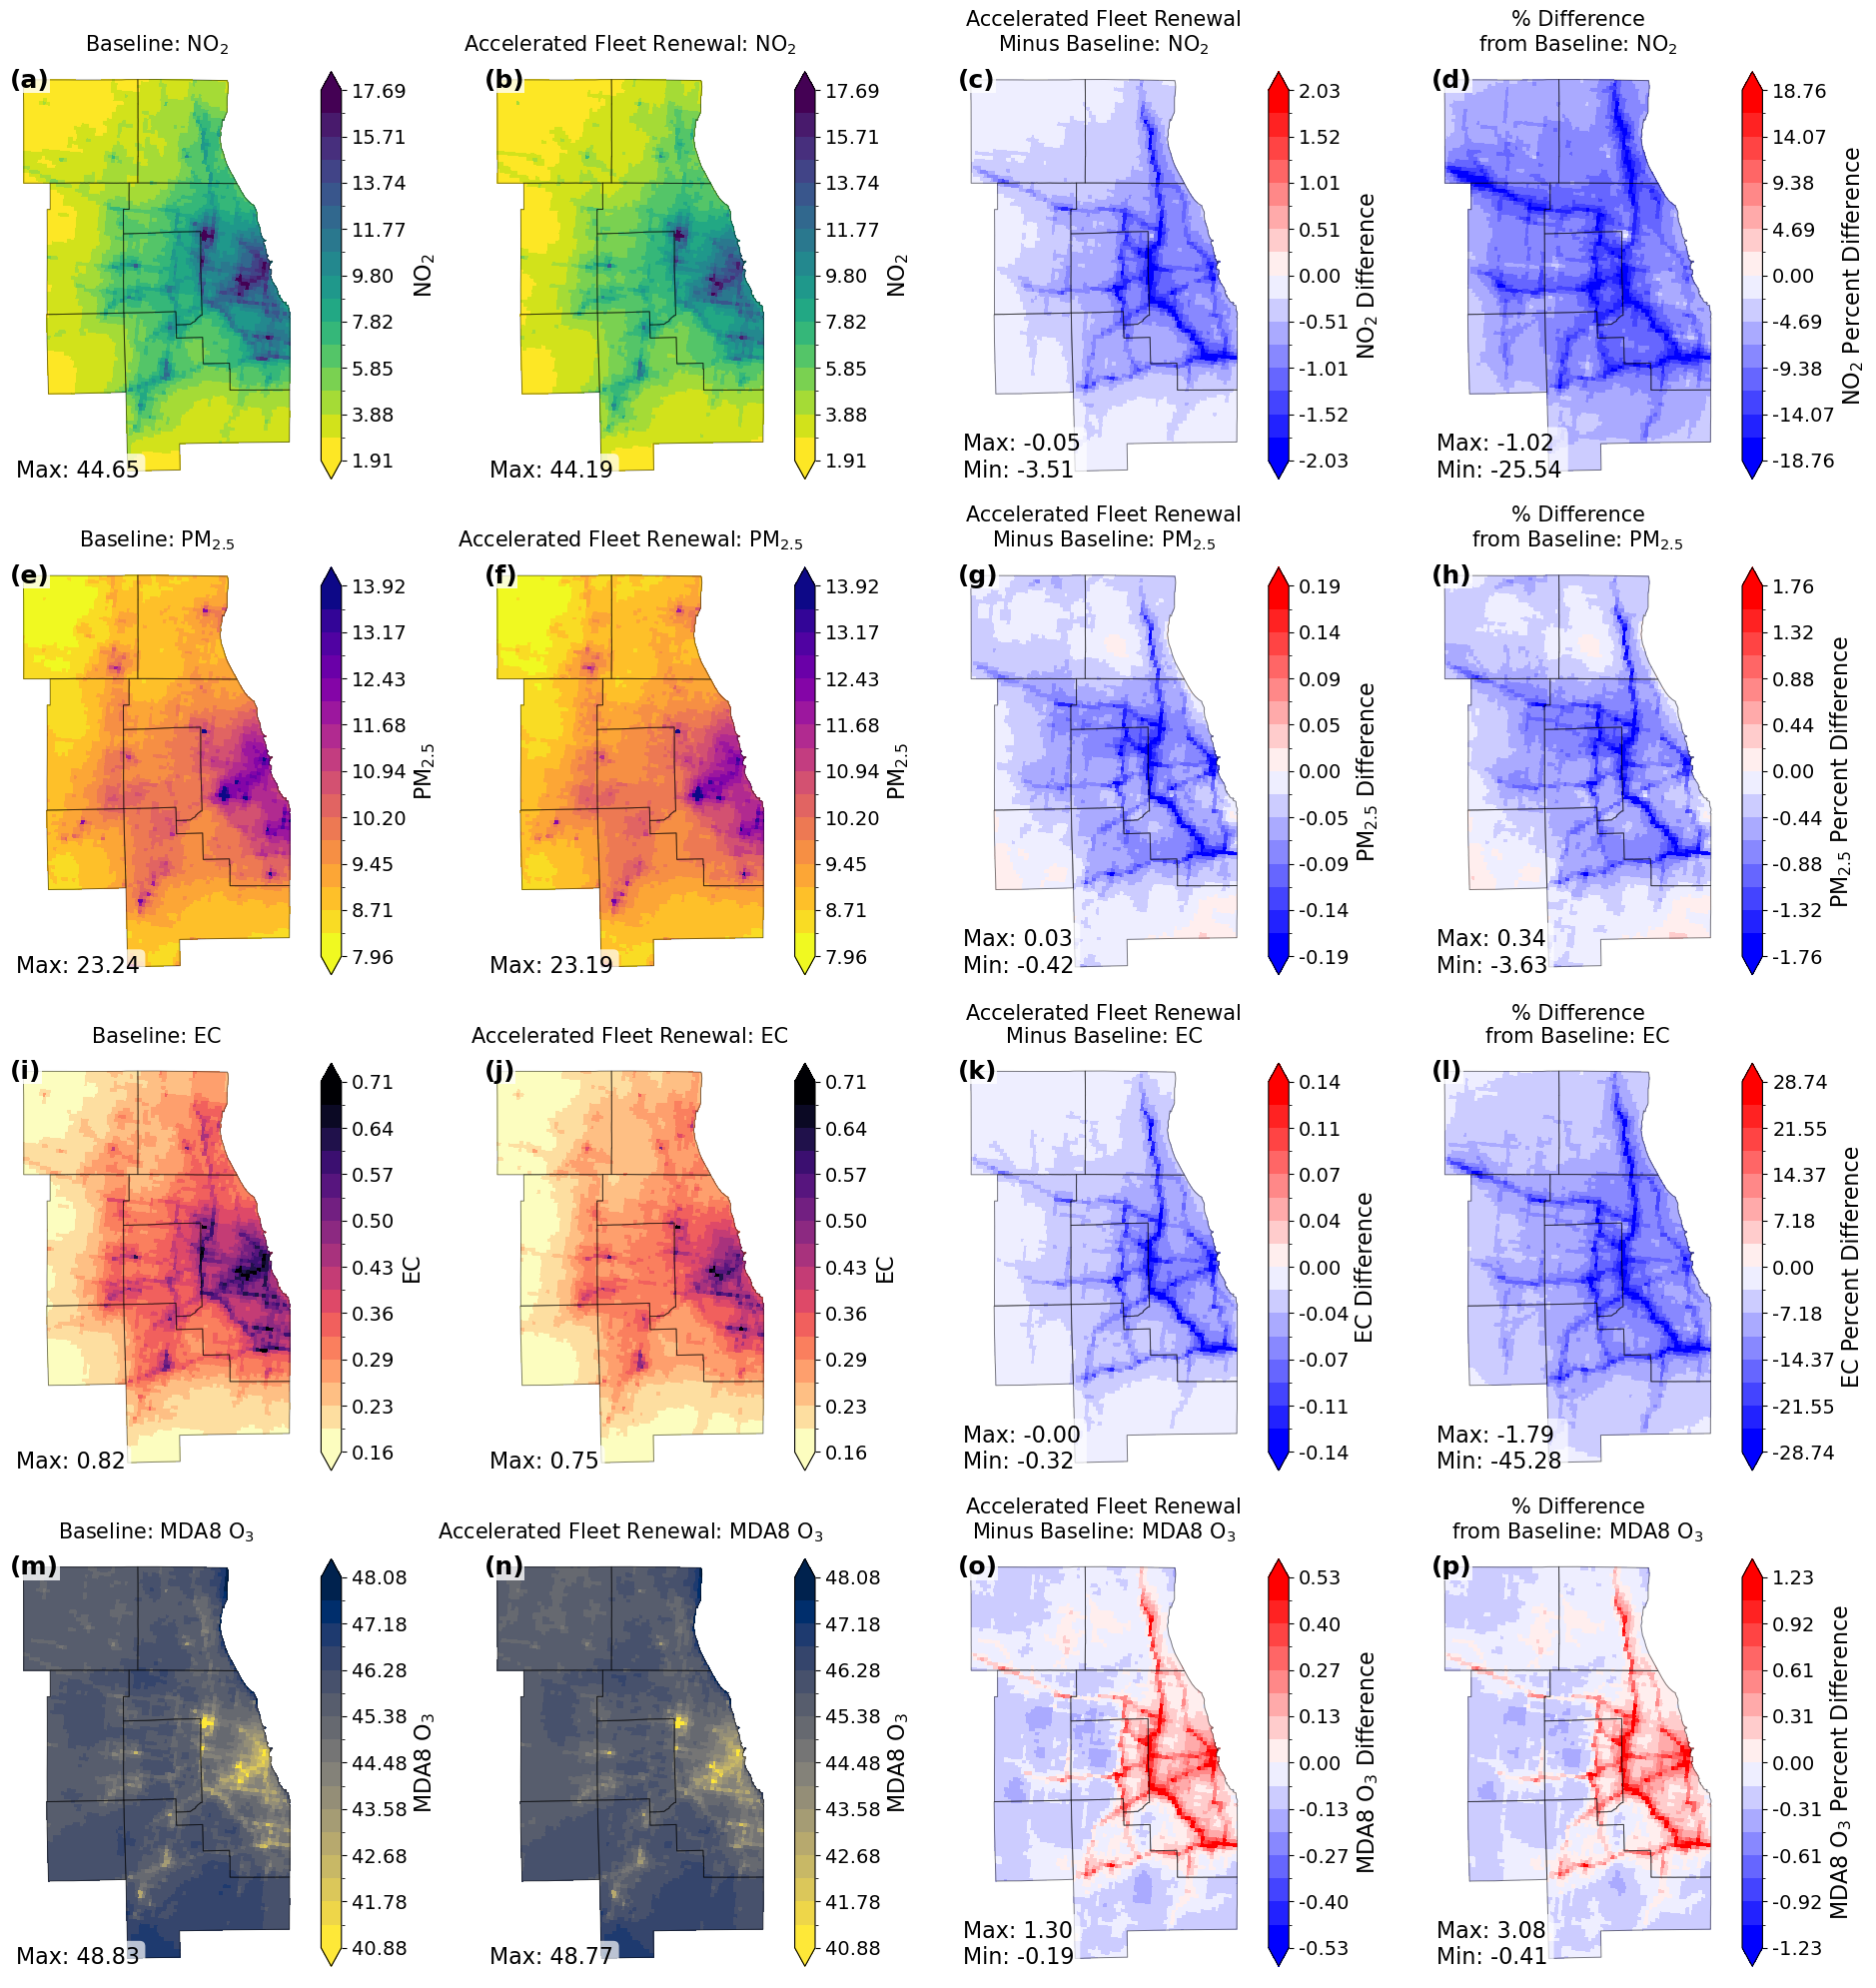

In [11]:
# plot annual average concentrations and changes under accelerated fleet renewal
N_BINS = 16
pollutants = ["NO2", "PM25_TOT", "PM25_EC", "O3"]
scenario_names = ["Baseline", "Accelerated Fleet Renewal", "Accelerated Fleet Renewal\nMinus Baseline", "% Difference\nfrom Baseline"]

# set the color scale and labels used for each pollutant
plot_config = {
    "NO2": {"cmap": "viridis_r", "title": "NO$_2$", "label": "NO$_2$", "column": "NO2"},
    "PM25_TOT": {"cmap": "plasma_r", "title": "PM$_{2.5}$", "label": "PM$_{2.5}$", "column": "PM25_TOT"},
    "PM25_EC": {"cmap": "magma_r", "title": "EC", "label": "EC", "column": "PM25_EC"},
    "O3": {"cmap": "cividis_r", "title": "MDA8 O$_3$", "label": "MDA8 O$_3$", "column": "O3"},
}

# pair the baseline and renewal files used for each pollutant
annual_gdfs_by_pol = {
    "NO2": {"reference": cmap_base_aconc, "scenario": cmap_renewal_aconc},
    "PM25_TOT": {"reference": cmap_base_aconc, "scenario": cmap_renewal_aconc},
    "PM25_EC": {"reference": cmap_base_aconc, "scenario": cmap_renewal_aconc},
    "O3": {"reference": cmap_base_o3, "scenario": cmap_renewal_o3},
}

# make a discrete color scale using the requested limits
def make_discrete_style(vmin, vmax, cmap_name):
    if np.isclose(vmin, vmax):
        vmax = vmin + 1e-6
    bounds = np.linspace(vmin, vmax, N_BINS + 1)
    cmap = ListedColormap(plt.colormaps[cmap_name](np.linspace(0, 1, N_BINS)))
    return {"bounds": bounds, "cmap": cmap, "norm": BoundaryNorm(bounds, cmap.N)}


def plot_annual_renewal():

    plot_data = {}
    plot_styles = {}

    # calculate the baseline, renewal, absolute difference, and percent difference
    for pol in pollutants:
        cfg = plot_config[pol]
        col = cfg["column"]
        reference_gdf = annual_gdfs_by_pol[pol]["reference"]
        scenario_gdf = annual_gdfs_by_pol[pol]["scenario"]

        reference_vals = reference_gdf[col].astype(float).to_numpy()
        scenario_vals = scenario_gdf[col].astype(float).to_numpy()
        diff_vals = scenario_vals - reference_vals

        pct_vals = np.full(diff_vals.shape, np.nan, dtype=float)
        np.divide(diff_vals, reference_vals, out=pct_vals, where=reference_vals != 0)
        pct_vals *= 100

        # use the same absolute scale for the baseline and renewal panels
        absolute_vals = np.concatenate([reference_vals[np.isfinite(reference_vals)], scenario_vals[np.isfinite(scenario_vals)]])
        absolute_min, absolute_max = np.quantile(absolute_vals, [0.001, 0.999])

        # center the difference scales around zero
        diff_lim = np.quantile(np.abs(diff_vals[np.isfinite(diff_vals)]), 0.99)
        pct_lim = np.quantile(np.abs(pct_vals[np.isfinite(pct_vals)]), 0.99)
        diff_lim = 1e-6 if np.isclose(diff_lim, 0) else diff_lim
        pct_lim = 1e-6 if np.isclose(pct_lim, 0) else pct_lim

        plot_styles[pol] = {
            "absolute": make_discrete_style(absolute_min, absolute_max, cfg["cmap"]),
            "difference": make_discrete_style(-diff_lim, diff_lim, "bwr"),
            "percent": make_discrete_style(-pct_lim, pct_lim, "bwr"),
        }

        # copy the geometry and add the values plotted in each panel
        plot_reference = reference_gdf.copy()
        plot_scenario = scenario_gdf.copy()
        plot_diff = scenario_gdf.copy()
        plot_pct = scenario_gdf.copy()

        plot_reference[pol] = reference_vals
        plot_scenario[pol] = scenario_vals
        plot_diff[pol] = diff_vals
        plot_pct[pol] = pct_vals

        plot_data[pol] = {
            scenario_names[0]: plot_reference,
            scenario_names[1]: plot_scenario,
            scenario_names[2]: plot_diff,
            scenario_names[3]: plot_pct,
        }

    # make one row for each pollutant and one column for each comparison
    fig, axs = plt.subplots(len(pollutants), len(scenario_names), figsize=(20, 20), subplot_kw={"projection": ccrs.PlateCarree()})

    for i, pol in enumerate(pollutants):
        cfg = plot_config[pol]

        for j, scenario_name in enumerate(scenario_names):
            ax = axs[i, j]
            gdf = plot_data[pol][scenario_name]
            style_name = "absolute" if j < 2 else "difference" if j == 2 else "percent"
            style = plot_styles[pol][style_name]

            # plot the gridded concentrations and county boundaries
            gdf.plot(column=pol, ax=ax, cmap=style["cmap"], norm=style["norm"], edgecolor="none", antialiased=False)
            cmap_cty.boundary.plot(ax=ax, color="black", alpha=0.5, linewidth=0.7)

            ax.set_title(f"{scenario_name}: {cfg['title']}", fontsize=15)
            ax.set_axis_off()

            # add the panel label in the upper-left corner
            panel_label = f"({chr(97 + i * len(scenario_names) + j)})"
            ax.text(0.001, 0.98, panel_label, transform=ax.transAxes, ha="left", va="top", fontsize=18, fontweight="bold", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 0.2})

            # add the color bar for each panel
            sm = plt.cm.ScalarMappable(norm=style["norm"], cmap=style["cmap"])
            cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04, boundaries=style["bounds"], ticks=style["bounds"][::2], spacing="proportional", extend="both")
            cbar.ax.tick_params(labelsize=14)
            cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

            if j == 2:
                cbar.set_label(f"{cfg['label']} Difference", fontsize=16)
            elif j == 3:
                cbar.set_label(f"{cfg['label']} Percent Difference", fontsize=16)
            else:
                cbar.set_label(cfg["label"], fontsize=16)

            # show the maximum for absolute concentrations and the range for changes
            vals = gdf[pol].astype(float).to_numpy()
            vals = vals[np.isfinite(vals)]
            annot_text = f"Max: {np.nanmax(vals):.2f}" if j < 2 else f"Max: {np.nanmax(vals):.2f}\nMin: {np.nanmin(vals):.2f}"
            ax.text(0.02, 0.02, annot_text, transform=ax.transAxes, ha="left", va="bottom", fontsize=16, color="black", bbox={"facecolor": "white", "alpha": 0.7, "boxstyle": "round,pad=0.25", "linewidth": 0})

    plt.tight_layout()
    plt.savefig("Fig_Annualized_Default_renewal_GriddedAirPoll_2023.png", dpi=500, bbox_inches="tight")
    plt.show()


plot_annual_renewal()

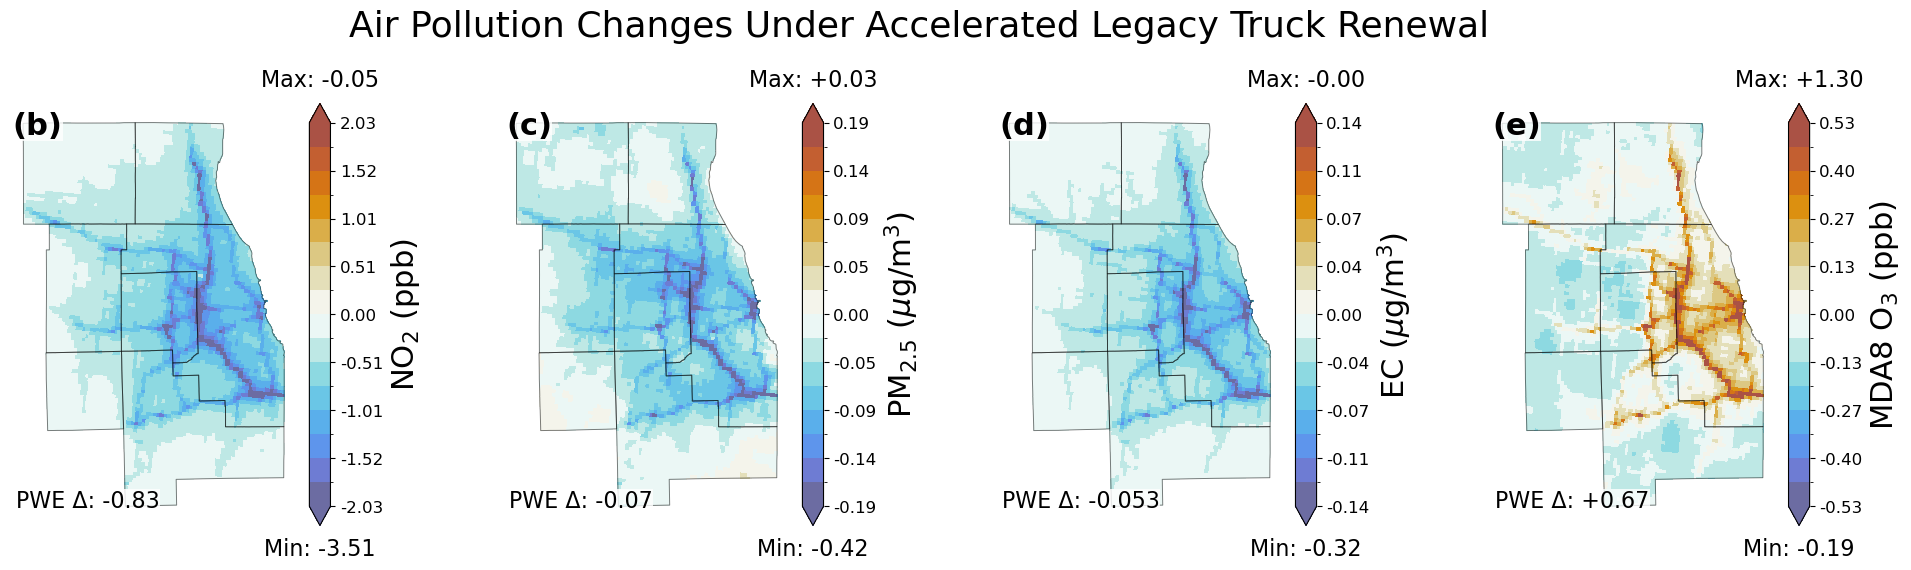

In [14]:
# plot the annual concentration changes under accelerated fleet renewal
N_BINS = 16
pollutants = ["NO2", "PM25_TOT", "PM25_EC", "O3"]

# set the labels and population-weighted exposure changes used in each panel
plot_config = {
    "NO2": {"label": "NO$_2$ (ppb)", "column": "NO2", "pwe_delta": 8.258354 - 9.087728, "pwe_decimals": 2},
    "PM25_TOT": {"label": "PM$_{2.5}$ ($\\mu$g/m$^{3}$)", "column": "PM25_TOT", "pwe_delta": 10.442088 - 10.512787, "pwe_decimals": 2},
    "PM25_EC": {"label": "EC ($\\mu$g/m$^{3}$)", "column": "PM25_EC", "pwe_delta": 0.353728 - 0.406834, "pwe_decimals": 3},
    "O3": {"label": "MDA8 O$_3$ (ppb)", "column": "O3", "pwe_delta": 34.693385 - 34.026842, "pwe_decimals": 2},}

# pair the baseline and renewal data used for each pollutant
annual_gdfs_by_pol = {
    "NO2": {"reference": cmap_base_aconc, "scenario": cmap_renewal_aconc},
    "PM25_TOT": {"reference": cmap_base_aconc, "scenario": cmap_renewal_aconc},
    "PM25_EC": {"reference": cmap_base_aconc, "scenario": cmap_renewal_aconc},
    "O3": {"reference": cmap_base_o3, "scenario": cmap_renewal_o3},}


def plot_annual_renewal_difference():

    fig, axs = plt.subplots(1, 4, figsize=(20, 5.5), subplot_kw={"projection": ccrs.PlateCarree()})
    fig.suptitle("Air Pollution Changes Under Accelerated Legacy Truck Renewal", fontsize=26, y=1.01)

    for i, pol in enumerate(pollutants):
        ax = axs[i]
        cfg = plot_config[pol]
        col = cfg["column"]
        reference_gdf = annual_gdfs_by_pol[pol]["reference"]
        scenario_gdf = annual_gdfs_by_pol[pol]["scenario"]

        # calculate the annual renewal-minus-baseline difference
        baseline_vals = reference_gdf[col].astype(float)
        renewal_vals = scenario_gdf[col].astype(float)
        diff_vals = renewal_vals - baseline_vals

        gdf = scenario_gdf.copy()
        gdf["difference"] = diff_vals

        # use the 99th percentile to keep the color scale centered around zero
        finite_vals = diff_vals.to_numpy()
        finite_vals = finite_vals[np.isfinite(finite_vals)]
        diff_lim = np.quantile(np.abs(finite_vals), 0.99)
        diff_lim = 1e-6 if np.isclose(diff_lim, 0) else diff_lim

        bounds = np.linspace(-diff_lim, diff_lim, N_BINS + 1)
        cmap_disc = ListedColormap(cmr.prinsenvlag_r(np.linspace(0, 1, N_BINS)))
        norm = BoundaryNorm(bounds, cmap_disc.N)

        # plot the concentration change and county boundaries
        gdf.plot(column="difference", ax=ax, cmap=cmap_disc, norm=norm, edgecolor="none", antialiased=False)
        cmap_cty.boundary.plot(ax=ax, color="black", alpha=0.5, linewidth=0.7)
        ax.set_axis_off()

        # continue the panel labels from panels a and b in the emissions figure
        ax.text(0.01, 0.98, f"({chr(98 + i)})", transform=ax.transAxes, ha="left", va="top", fontsize=22, fontweight="bold", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 0.2}, zorder=10)

        # add the pollutant-specific color bar
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap_disc)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax, fraction=0.06, pad=0.03, boundaries=bounds, ticks=bounds[::2], spacing="proportional", extend="both")
        cbar.ax.tick_params(labelsize=12)
        cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
        cbar.set_label(cfg["label"], fontsize=22)

        # show the actual modeled range outside the color bar
        vmax_actual = float(np.nanmax(finite_vals))
        vmin_actual = float(np.nanmin(finite_vals))
        cbar.ax.text(0.5, 1.08, f"Max: {vmax_actual:+.2f}", transform=cbar.ax.transAxes, ha="center", va="bottom", fontsize=16)
        cbar.ax.text(0.5, -0.08, f"Min: {vmin_actual:+.2f}", transform=cbar.ax.transAxes, ha="center", va="top", fontsize=16)

        # add the CMAP population-weighted exposure change
        ax.text(0.02, 0.03, f"PWE Δ: {cfg['pwe_delta']:+.{cfg['pwe_decimals']}f}", transform=ax.transAxes, ha="left", va="bottom", fontsize=16, bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 0.25}, zorder=10)

    plt.tight_layout()
    # save the figure
    # plt.savefig("Fig2_Renewal_Minus_Baseline_Concentrations_2023.png", dpi=500, bbox_inches="tight")
    plt.show()

plot_annual_renewal_difference()

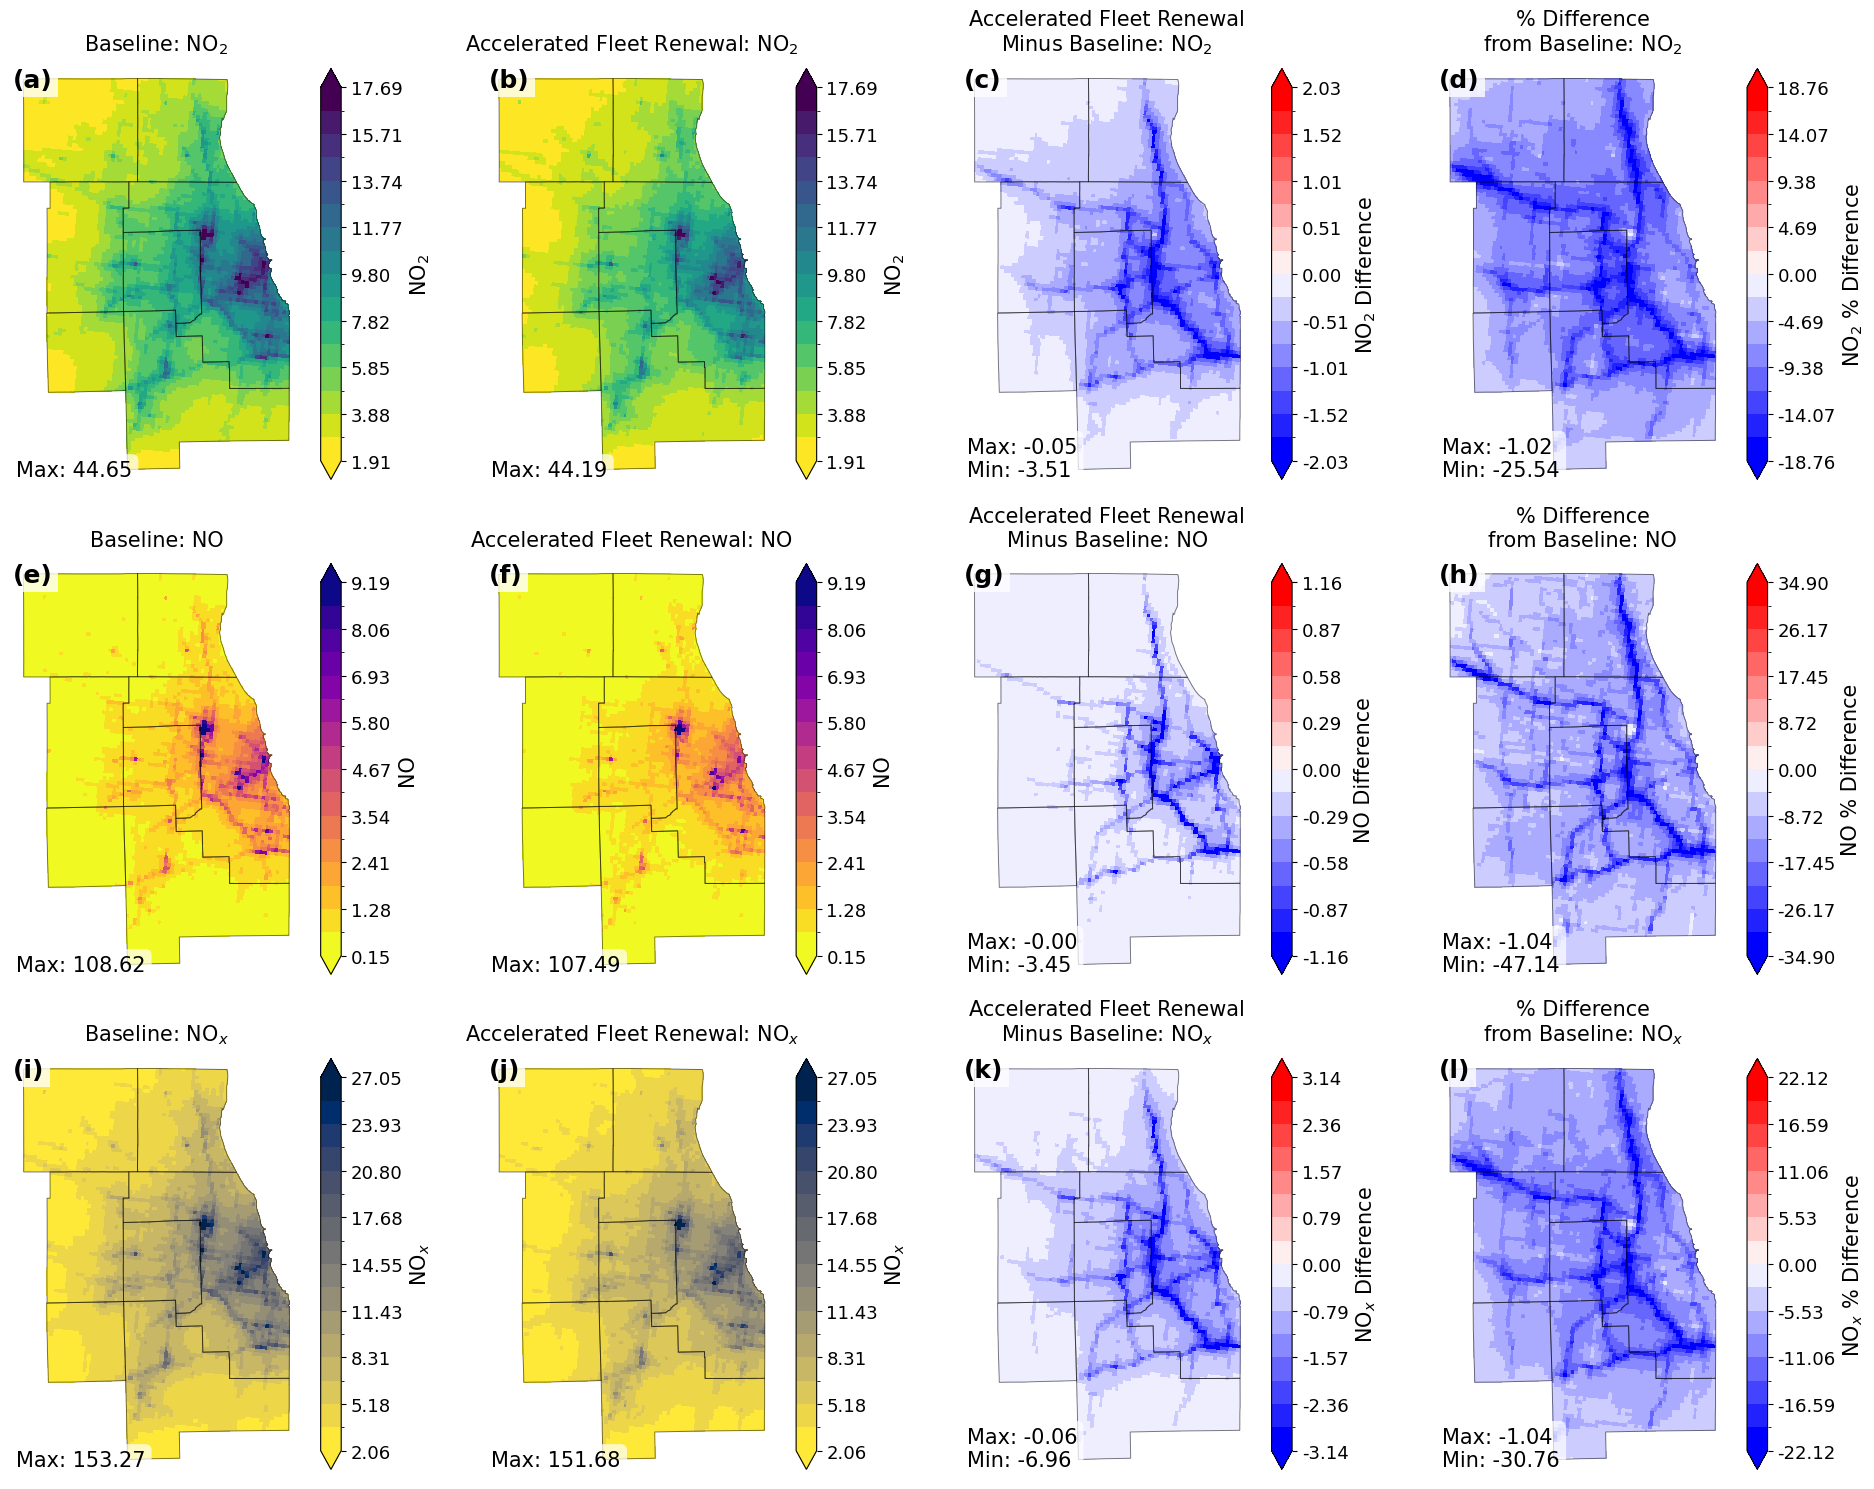

In [15]:
# plot annual baseline and accelerated fleet renewal NOx concentrations
N_BINS = 16
pollutants = ["NO2", "NO", "NOX"]
scenario_names = ["Baseline", "Accelerated Fleet Renewal", "Accelerated Fleet Renewal\nMinus Baseline", "% Difference\nfrom Baseline"]

# set the color scale and labels used for each pollutant
plot_config = {
    "NO2": {"cmap": "viridis_r", "title": "NO$_2$", "label": "NO$_2$", "column": "NO2"},
    "NO": {"cmap": "plasma_r", "title": "NO", "label": "NO", "column": "NO"},
    "NOX": {"cmap": "cividis_r", "title": "NO$_x$", "label": "NO$_x$", "column": "NOX"},
}

# use the baseline and renewal ACONC files for all three pollutants
annual_gdfs_by_pol = {pol: {"reference": cmap_base_aconc, "scenario": cmap_renewal_aconc} for pol in pollutants}


# make a discrete color scale using the requested limits
def make_discrete_style(vmin, vmax, cmap_name):
    if np.isclose(vmin, vmax):
        vmax = vmin + 1e-6
    bounds = np.linspace(vmin, vmax, N_BINS + 1)
    cmap = ListedColormap(plt.colormaps[cmap_name](np.linspace(0, 1, N_BINS)))
    return {"cmap": cmap, "bounds": bounds, "norm": BoundaryNorm(bounds, cmap.N)}


def plot_annual_nox():

    plot_data = {}
    plot_styles = {}

    # calculate the baseline, renewal, absolute difference, and percent difference
    for pol in pollutants:
        cfg = plot_config[pol]
        col = cfg["column"]
        reference_gdf = annual_gdfs_by_pol[pol]["reference"]
        scenario_gdf = annual_gdfs_by_pol[pol]["scenario"]

        reference_vals = reference_gdf[col].astype(float).to_numpy()
        scenario_vals = scenario_gdf[col].astype(float).to_numpy()
        diff_vals = scenario_vals - reference_vals

        pct_vals = np.full(diff_vals.shape, np.nan, dtype=float)
        np.divide(diff_vals, reference_vals, out=pct_vals, where=reference_vals != 0)
        pct_vals *= 100

        # use the same absolute color scale for the baseline and renewal panels
        absolute_vals = np.concatenate([reference_vals[np.isfinite(reference_vals)], scenario_vals[np.isfinite(scenario_vals)]])
        absolute_min, absolute_max = np.quantile(absolute_vals, [0.001, 0.999])

        # center the difference color scales around zero
        diff_lim = max(np.quantile(np.abs(diff_vals[np.isfinite(diff_vals)]), 0.99), 1e-6)
        pct_lim = max(np.quantile(np.abs(pct_vals[np.isfinite(pct_vals)]), 0.99), 1e-6)

        plot_styles[pol] = {
            "absolute": make_discrete_style(absolute_min, absolute_max, cfg["cmap"]),
            "difference": make_discrete_style(-diff_lim, diff_lim, "bwr"),
            "percent": make_discrete_style(-pct_lim, pct_lim, "bwr"),
        }

        # copy the geometry and add the values plotted in each panel
        plot_reference = reference_gdf.copy()
        plot_scenario = scenario_gdf.copy()
        plot_diff = scenario_gdf.copy()
        plot_pct = scenario_gdf.copy()

        plot_reference[pol] = reference_vals
        plot_scenario[pol] = scenario_vals
        plot_diff[pol] = diff_vals
        plot_pct[pol] = pct_vals

        plot_data[pol] = {
            scenario_names[0]: plot_reference,
            scenario_names[1]: plot_scenario,
            scenario_names[2]: plot_diff,
            scenario_names[3]: plot_pct,
        }

    # make one row for each pollutant and one column for each comparison
    fig, axs = plt.subplots(3, 4, figsize=(20, 15), subplot_kw={"projection": ccrs.PlateCarree()})

    for i, pol in enumerate(pollutants):
        cfg = plot_config[pol]

        for j, scenario_name in enumerate(scenario_names):
            ax = axs[i, j]
            gdf = plot_data[pol][scenario_name]
            style_name = "absolute" if j < 2 else "difference" if j == 2 else "percent"
            style = plot_styles[pol][style_name]

            # plot the gridded concentrations and county boundaries
            gdf.plot(column=pol, ax=ax, cmap=style["cmap"], norm=style["norm"], edgecolor="none", antialiased=False)
            cmap_cty.boundary.plot(ax=ax, color="black", linewidth=0.7, alpha=0.5)

            ax.set_title(f"{scenario_name}: {cfg['title']}", fontsize=15)
            ax.set_axis_off()

            # add the panel label in the upper-left corner
            panel_label = f"({chr(97 + i * len(scenario_names) + j)})"
            ax.text(0.01, 0.98, panel_label, transform=ax.transAxes, ha="left", va="top", fontsize=18, fontweight="bold", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"})

            # add the color bar for each panel
            sm = plt.cm.ScalarMappable(norm=style["norm"], cmap=style["cmap"])
            sm.set_array([])
            cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04, boundaries=style["bounds"], ticks=style["bounds"][::2], extend="both")
            cbar.ax.tick_params(labelsize=13)
            cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

            if j == 2:
                cbar.set_label(f"{cfg['label']} Difference", fontsize=15)
            elif j == 3:
                cbar.set_label(f"{cfg['label']} % Difference", fontsize=15)
            else:
                cbar.set_label(cfg["label"], fontsize=15)

            # show the maximum for concentrations and the range for changes
            vals = gdf[pol].astype(float).to_numpy()
            vals = vals[np.isfinite(vals)]
            summary_text = f"Max: {np.nanmax(vals):.2f}" if j < 2 else f"Max: {np.nanmax(vals):.2f}\nMin: {np.nanmin(vals):.2f}"
            ax.text(0.02, 0.02, summary_text, transform=ax.transAxes, ha="left", va="bottom", fontsize=15, bbox={"facecolor": "white", "alpha": 0.7, "boxstyle": "round", "linewidth": 0})

    plt.tight_layout()
    #plt.savefig("Fig_Annualized_NO2_NO_NOX_Renewal.png", dpi=500, bbox_inches="tight")
    plt.show()


plot_annual_nox()

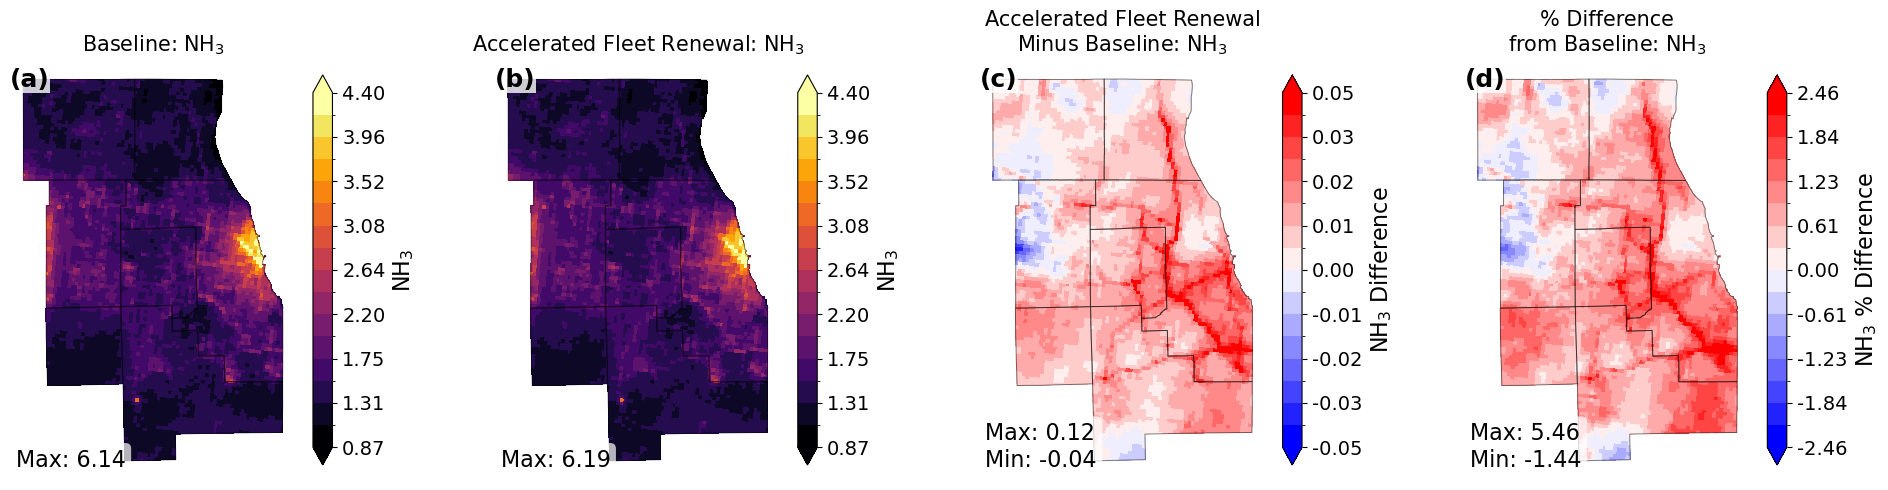

In [16]:
# plot annual baseline and accelerated fleet renewal NH3 concentrations
N_BINS = 16
pollutant = "NH3"
scenario_names = ["Baseline", "Accelerated Fleet Renewal", "Accelerated Fleet Renewal\nMinus Baseline", "% Difference\nfrom Baseline"]
plot_config = {"cmap": "inferno", "title": "NH$_3$", "label": "NH$_3$", "column": "NH3"}


# make a discrete color scale using the requested limits
def make_discrete_style(vmin, vmax, cmap_name):
    if np.isclose(vmin, vmax):
        vmax = vmin + 1e-6
    bounds = np.linspace(vmin, vmax, N_BINS + 1)
    cmap = ListedColormap(plt.colormaps[cmap_name](np.linspace(0, 1, N_BINS)))
    return {"bounds": bounds, "cmap": cmap, "norm": BoundaryNorm(bounds, cmap.N)}


def plot_annual_nh3():

    col = plot_config["column"]
    reference_gdf = cmap_base_aconc
    scenario_gdf = cmap_renewal_aconc

    # calculate the baseline, renewal, absolute difference, and percent difference
    reference_vals = reference_gdf[col].astype(float).to_numpy()
    scenario_vals = scenario_gdf[col].astype(float).to_numpy()
    diff_vals = scenario_vals - reference_vals

    pct_vals = np.full(diff_vals.shape, np.nan, dtype=float)
    np.divide(diff_vals, reference_vals, out=pct_vals, where=reference_vals != 0)
    pct_vals *= 100

    # use the same absolute color scale for the baseline and renewal panels
    absolute_vals = np.concatenate([reference_vals[np.isfinite(reference_vals)], scenario_vals[np.isfinite(scenario_vals)]])
    absolute_min, absolute_max = np.quantile(absolute_vals, [0.001, 0.999])

    # center the difference color scales around zero
    diff_lim = max(np.quantile(np.abs(diff_vals[np.isfinite(diff_vals)]), 0.99), 1e-6)
    pct_lim = max(np.quantile(np.abs(pct_vals[np.isfinite(pct_vals)]), 0.99), 1e-6)

    absolute_style = make_discrete_style(absolute_min, absolute_max, plot_config["cmap"])
    difference_style = make_discrete_style(-diff_lim, diff_lim, "bwr")
    percent_style = make_discrete_style(-pct_lim, pct_lim, "bwr")

    plot_values = [reference_vals, scenario_vals, diff_vals, pct_vals]
    plot_sources = [reference_gdf, scenario_gdf, scenario_gdf, scenario_gdf]
    plot_styles = [absolute_style, absolute_style, difference_style, percent_style]

    # make one panel for each comparison
    fig, axs = plt.subplots(1, 4, figsize=(20, 5), subplot_kw={"projection": ccrs.PlateCarree()})

    for j, scenario_name in enumerate(scenario_names):
        ax = axs[j]
        style = plot_styles[j]
        gdf = plot_sources[j].copy()
        gdf[pollutant] = plot_values[j]

        # plot the gridded concentrations and county boundaries
        gdf.plot(column=pollutant, ax=ax, cmap=style["cmap"], norm=style["norm"], edgecolor="none", antialiased=False)
        cmap_cty.boundary.plot(ax=ax, color="black", alpha=0.5, linewidth=0.7)

        ax.set_title(f"{scenario_name}: {plot_config['title']}", fontsize=15)
        ax.set_axis_off()

        # add the panel label in the upper-left corner
        ax.text(0.001, 0.98, f"({chr(97 + j)})", transform=ax.transAxes, ha="left", va="top", fontsize=18, fontweight="bold", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 0.2})

        # add the color bar for each panel
        sm = plt.cm.ScalarMappable(norm=style["norm"], cmap=style["cmap"])
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04, boundaries=style["bounds"], ticks=style["bounds"][::2], spacing="proportional", extend="both")
        cbar.ax.tick_params(labelsize=14)
        cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

        if j == 2:
            cbar.set_label(f"{plot_config['label']} Difference", fontsize=16)
        elif j == 3:
            cbar.set_label(f"{plot_config['label']} % Difference", fontsize=16)
        else:
            cbar.set_label(plot_config["label"], fontsize=16)

        # show the maximum for concentrations and the range for changes
        finite_vals = plot_values[j][np.isfinite(plot_values[j])]
        annot_text = f"Max: {np.nanmax(finite_vals):.2f}" if j < 2 else f"Max: {np.nanmax(finite_vals):.2f}\nMin: {np.nanmin(finite_vals):.2f}"
        ax.text(0.02, 0.02, annot_text, transform=ax.transAxes, ha="left", va="bottom", fontsize=16, color="black", bbox={"facecolor": "white", "alpha": 0.7, "boxstyle": "round,pad=0.25", "linewidth": 0})

    plt.tight_layout()
    #plt.savefig("Fig_Annualized_Default_Renewal_NH3_2023.png", dpi=500, bbox_inches="tight")
    plt.show()

plot_annual_nh3()

In [17]:
for gdf in [cmap_base_aconc, cmap_renewal_aconc]:
    gdf["Primary_PM25"] = gdf[primary_pm_species].sum(axis=1)
    gdf["Secondary_PM25"] = gdf[secondary_pm_species].sum(axis=1)

pm25_groups = {
    "Primary_PM25": {
        "title": "Primary-associated\nPM$_{2.5}$",
        "label": "Primary PM$_{2.5}$",
        "cmap_name": "magma_r", },
    "Secondary_PM25": {
        "title": "Secondary PM$_{2.5}$",
        "label": "Secondary PM$_{2.5}$",
        "cmap_name": "plasma_r",},
}

scenario_names = [
    "Baseline",
    "Accelerated Fleet Renewal",
    "Accelerated Fleet Renewal\nMinus Baseline",
    "% Difference\nfrom Baseline",]

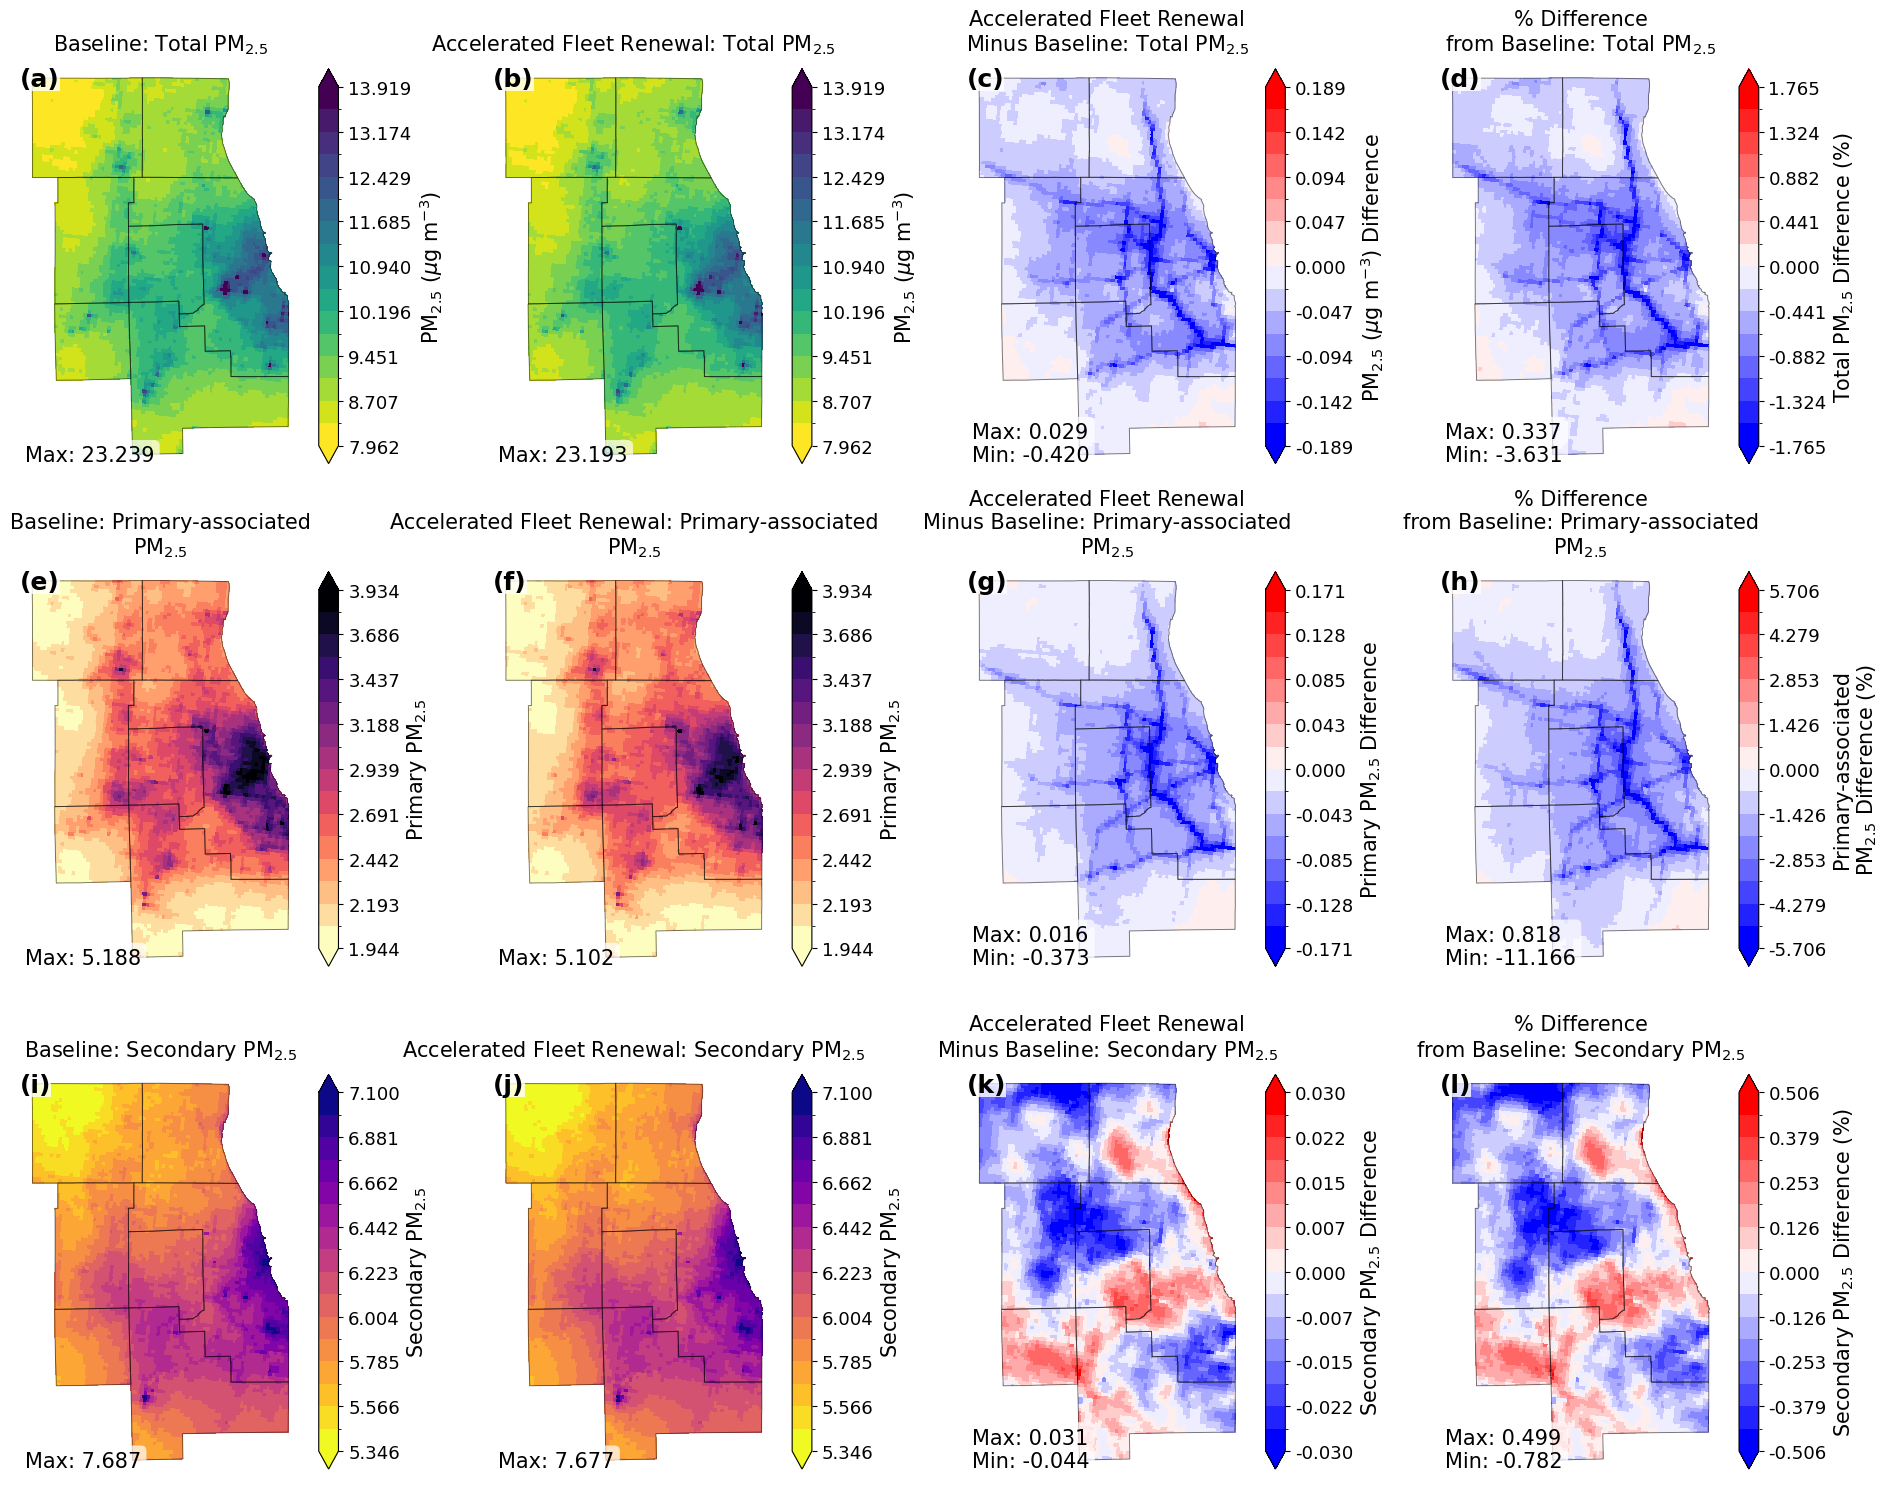

In [18]:
# plot annual total, primary-associated, and secondary-associated PM2.5
N_BINS = 16
scenario_names = ["Baseline", "Accelerated Fleet Renewal", "Accelerated Fleet Renewal\nMinus Baseline", "% Difference\nfrom Baseline"]


# make a discrete color scale using the requested limits
def make_discrete_style(vmin, vmax, cmap_name):
    if np.isclose(vmin, vmax):
        vmax = vmin + 1e-6
    bounds = np.linspace(vmin, vmax, N_BINS + 1)
    cmap = ListedColormap(plt.colormaps[cmap_name](np.linspace(0, 1, N_BINS)))
    return {"bounds": bounds, "cmap": cmap, "norm": BoundaryNorm(bounds, cmap.N)}


def plot_primary_secondary_pm25():

    # add total PM2.5 above the primary- and secondary-associated groups
    plot_groups = {"PM25_TOT": {"cmap_name": "viridis_r", "title": "Total PM$_{2.5}$", "label": "PM$_{2.5}$ ($\\mu$g m$^{-3}$)"}, **pm25_groups}
    plot_data = {}
    plot_styles = {}

    for pm_group, cfg in plot_groups.items():

        # calculate the baseline, renewal, absolute difference, and percent difference
        base_vals = cmap_base_aconc[pm_group].astype(float).to_numpy()
        renewal_vals = cmap_renewal_aconc[pm_group].astype(float).to_numpy()
        diff_vals = renewal_vals - base_vals

        pct_vals = np.full(diff_vals.shape, np.nan, dtype=float)
        np.divide(diff_vals, base_vals, out=pct_vals, where=base_vals != 0)
        pct_vals *= 100

        # use the same absolute color scale for the baseline and renewal panels
        absolute_vals = np.concatenate([base_vals[np.isfinite(base_vals)], renewal_vals[np.isfinite(renewal_vals)]])
        absolute_min, absolute_max = np.quantile(absolute_vals, [0.001, 0.999])

        # center the difference color scales around zero
        diff_lim = max(np.quantile(np.abs(diff_vals[np.isfinite(diff_vals)]), 0.99), 1e-6)
        pct_lim = max(np.quantile(np.abs(pct_vals[np.isfinite(pct_vals)]), 0.99), 1e-6)

        plot_styles[pm_group] = {
            "absolute": make_discrete_style(absolute_min, absolute_max, cfg["cmap_name"]),
            "difference": make_discrete_style(-diff_lim, diff_lim, "bwr"),
            "percent": make_discrete_style(-pct_lim, pct_lim, "bwr"),
        }

        plot_data[pm_group] = {
            "values": [base_vals, renewal_vals, diff_vals, pct_vals],
            "sources": [cmap_base_aconc, cmap_renewal_aconc, cmap_renewal_aconc, cmap_renewal_aconc],
        }

    # make one row for each PM2.5 group and one column for each comparison
    fig, axs = plt.subplots(len(plot_groups), len(scenario_names), figsize=(20, 5 * len(plot_groups)), subplot_kw={"projection": ccrs.PlateCarree()})

    # add a title when needed
    # fig.suptitle("Annualized 2023 Total, Primary-Associated, and Secondary-Associated PM$_{2.5}$", fontsize=24, y=1.01)

    for i, (pm_group, cfg) in enumerate(plot_groups.items()):
        values = plot_data[pm_group]["values"]
        sources = plot_data[pm_group]["sources"]

        for j, scenario_name in enumerate(scenario_names):
            ax = axs[i, j]
            style_name = "absolute" if j < 2 else "difference" if j == 2 else "percent"
            style = plot_styles[pm_group][style_name]

            # copy the geometry and add the values plotted in this panel
            gdf = sources[j].copy()
            gdf[pm_group] = values[j]

            # plot the spatial field and county boundaries
            gdf.plot(column=pm_group, ax=ax, cmap=style["cmap"], norm=style["norm"], edgecolor="none", antialiased=False)
            cmap_cty.boundary.plot(ax=ax, color="black", alpha=0.5, linewidth=0.7)

            ax.set_title(f"{scenario_name}: {cfg['title']}", fontsize=15)
            ax.set_axis_off()

            # add the panel label in the upper-left corner
            panel_label = f"({chr(97 + i * len(scenario_names) + j)})"
            ax.text(0.001, 0.98, panel_label, transform=ax.transAxes, ha="left", va="top", fontsize=18, fontweight="bold", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 0.2}, zorder=10)

            # add the color bar for each panel
            sm = plt.cm.ScalarMappable(norm=style["norm"], cmap=style["cmap"])
            sm.set_array([])
            cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04, boundaries=style["bounds"], ticks=style["bounds"][::2], spacing="proportional", extend="both")
            cbar.ax.tick_params(labelsize=13)
            cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.3f"))

            if j == 2:
                cbar.set_label(f"{cfg['label']} Difference", fontsize=15)
            elif j == 3:
                cbar.set_label(f"{cfg['title']} Difference (%)", fontsize=15)
            else:
                cbar.set_label(cfg["label"], fontsize=15)

            # show the maximum for concentrations and the range for changes
            finite_vals = values[j][np.isfinite(values[j])]
            annot_text = f"Max: {np.nanmax(finite_vals):.3f}" if j < 2 else f"Max: {np.nanmax(finite_vals):.3f}\nMin: {np.nanmin(finite_vals):.3f}"
            ax.text(0.02, 0.02, annot_text, transform=ax.transAxes, ha="left", va="bottom", fontsize=15, color="black", bbox={"facecolor": "white", "alpha": 0.7, "boxstyle": "round,pad=0.25", "linewidth": 0}, zorder=10)

    plt.tight_layout()
    #plt.savefig("SI_Annualized_Default_Renewal_TotalPrimarySecondaryPM25_2023.png", dpi=500, bbox_inches="tight")
    plt.show()


plot_primary_secondary_pm25()

<h1> Plot Legacy Fleet Removal and Locus Idling + On-road Modification

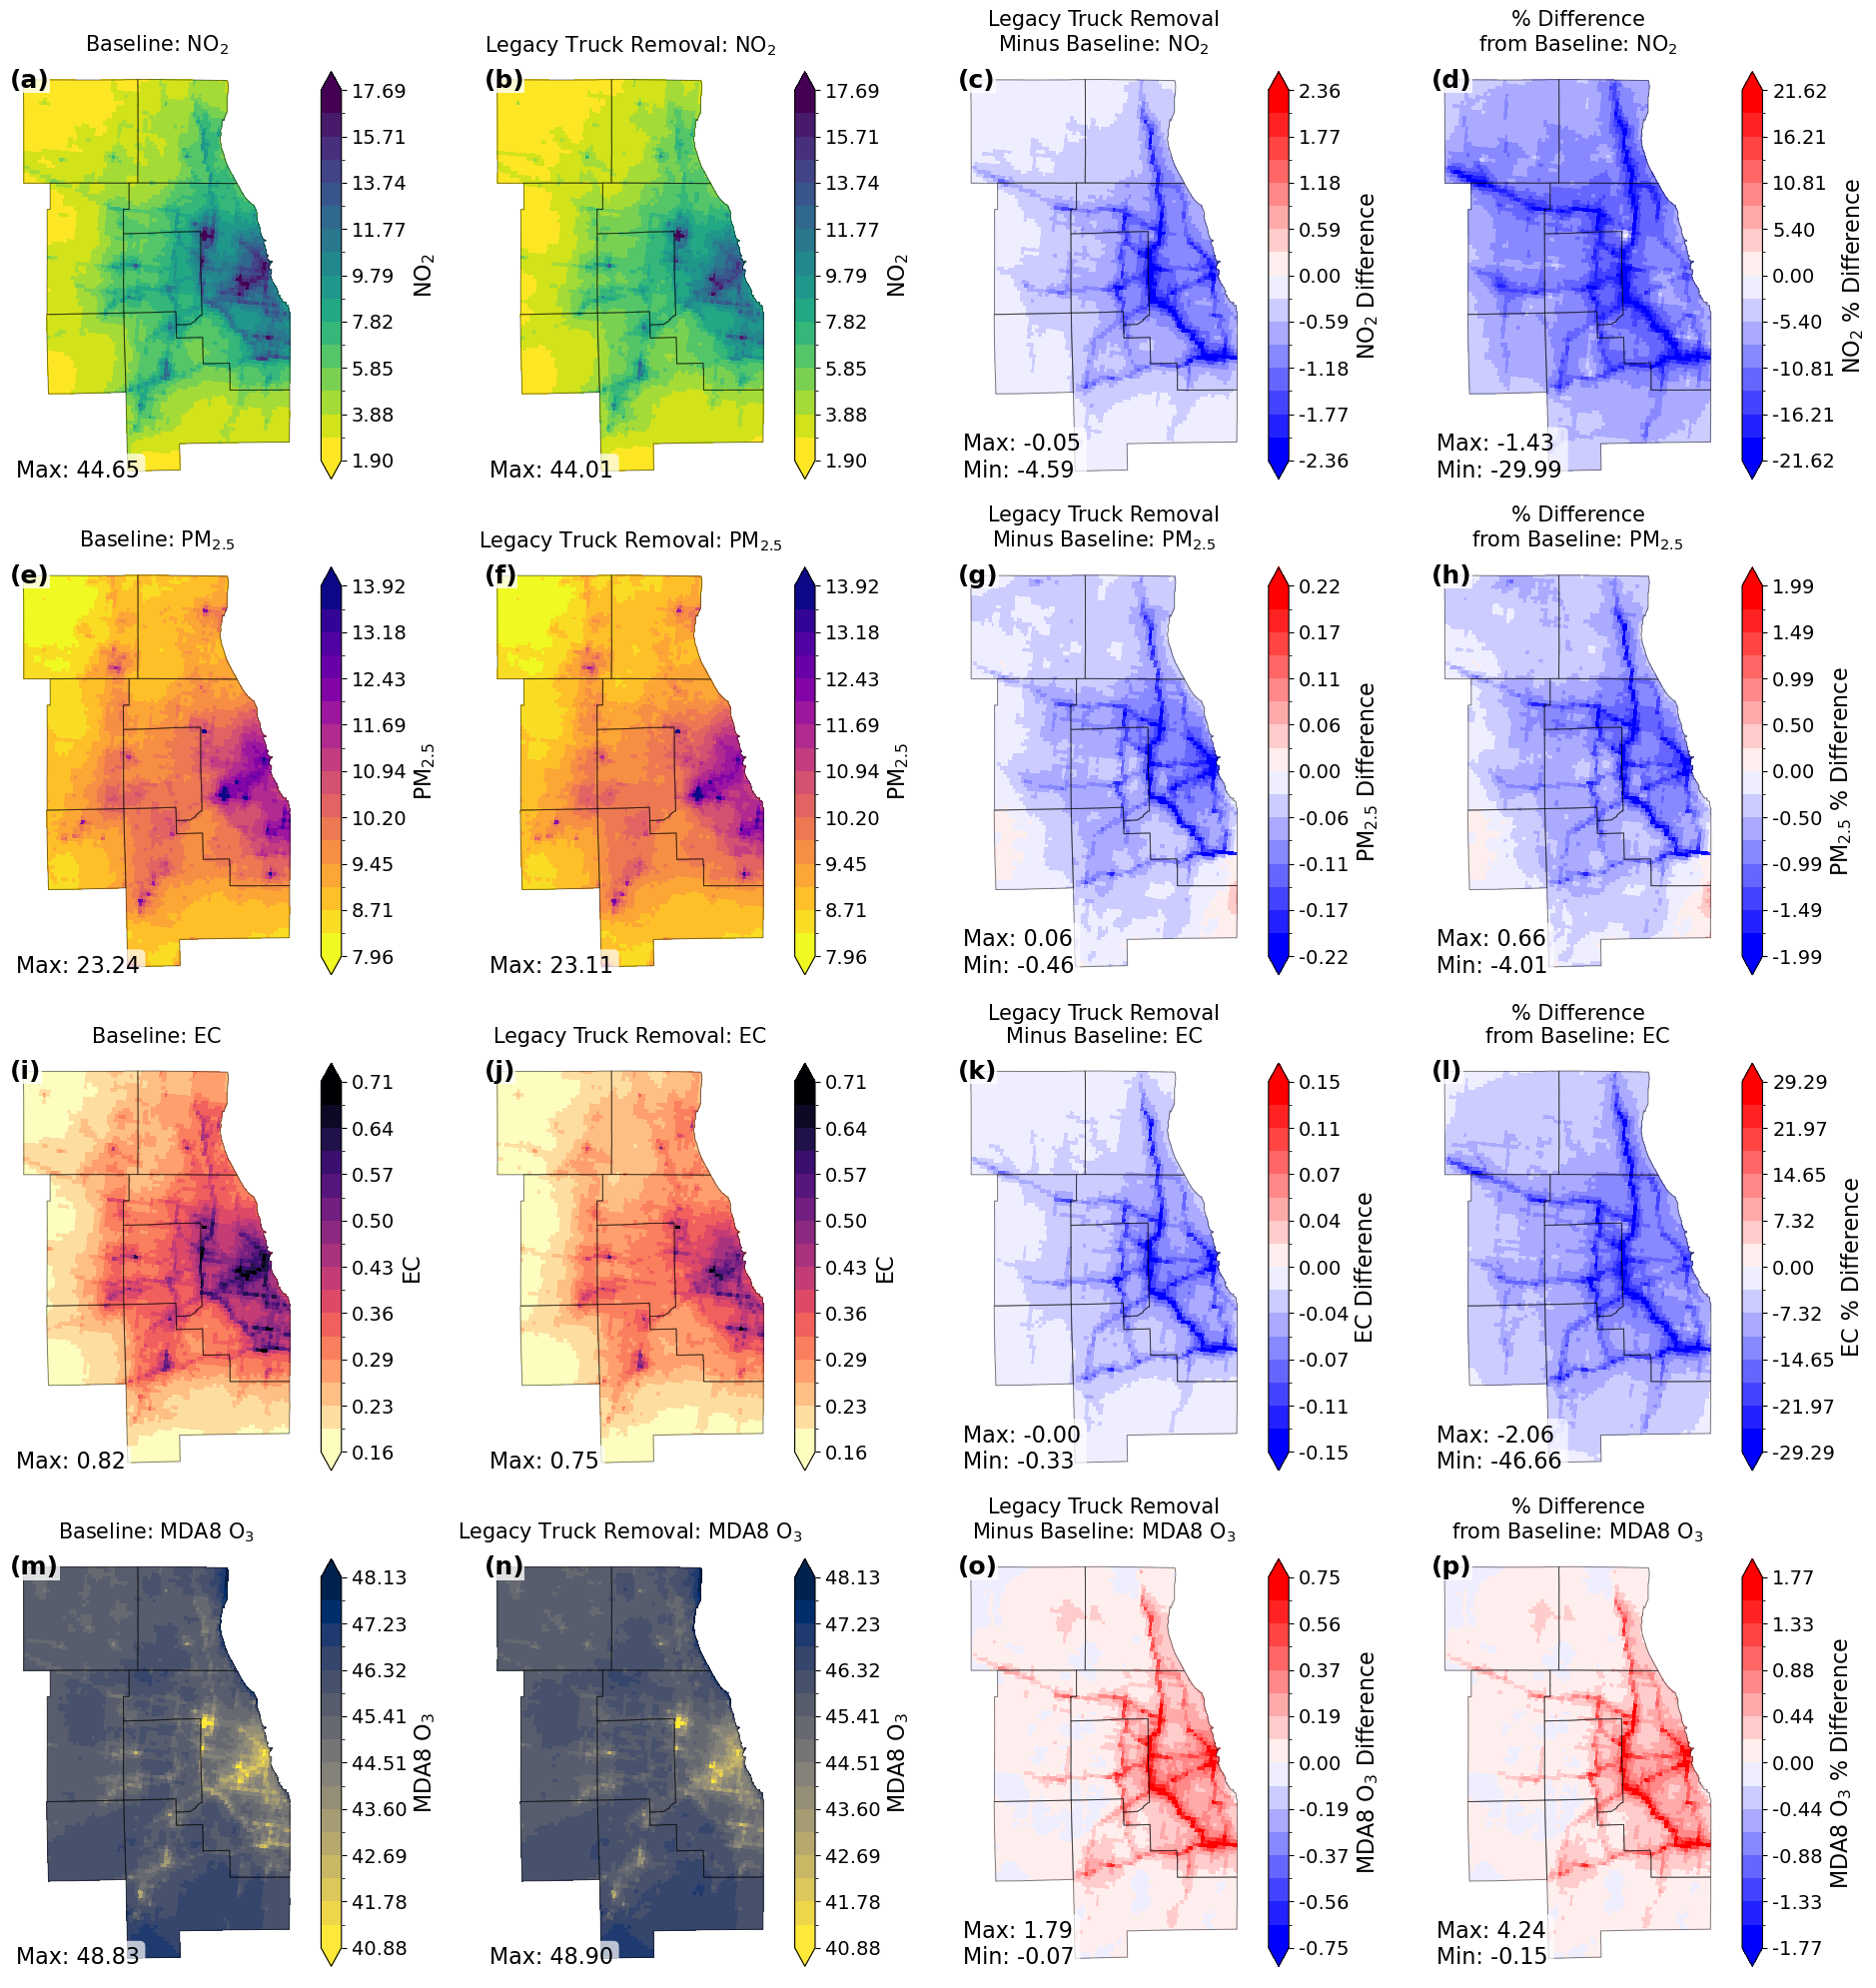

In [19]:
# plot annual baseline and legacy truck removal concentrations
N_BINS = 16
pollutants = ["NO2", "PM25_TOT", "PM25_EC", "O3"]
scenario_names = ["Baseline", "Legacy Truck Removal", "Legacy Truck Removal\nMinus Baseline", "% Difference\nfrom Baseline"]

# set the color scale and labels used for each pollutant
plot_config = {
    "NO2": {"cmap": "viridis_r", "title": "NO$_2$", "label": "NO$_2$", "column": "NO2"},
    "PM25_TOT": {"cmap": "plasma_r", "title": "PM$_{2.5}$", "label": "PM$_{2.5}$", "column": "PM25_TOT"},
    "PM25_EC": {"cmap": "magma_r", "title": "EC", "label": "EC", "column": "PM25_EC"},
    "O3": {"cmap": "cividis_r", "title": "MDA8 O$_3$", "label": "MDA8 O$_3$", "column": "O3"},
}

# pair the baseline and legacy truck removal data used for each pollutant
annual_gdfs_by_pol = {
    "NO2": {"reference": cmap_base_aconc, "scenario": cmap_zeropre2010s_aconc},
    "PM25_TOT": {"reference": cmap_base_aconc, "scenario": cmap_zeropre2010s_aconc},
    "PM25_EC": {"reference": cmap_base_aconc, "scenario": cmap_zeropre2010s_aconc},
    "O3": {"reference": cmap_base_o3, "scenario": cmap_zeropre2010s_o3},
}


# make a discrete color scale using the requested limits
def make_discrete_style(vmin, vmax, cmap_name):
    if np.isclose(vmin, vmax):
        vmax = vmin + 1e-6
    bounds = np.linspace(vmin, vmax, N_BINS + 1)
    cmap = ListedColormap(plt.colormaps[cmap_name](np.linspace(0, 1, N_BINS)))
    return {"bounds": bounds, "cmap": cmap, "norm": BoundaryNorm(bounds, cmap.N)}


def plot_annual_legacy_removal():

    plot_data = {}
    plot_styles = {}

    # calculate the baseline, removal, absolute difference, and percent difference
    for pol in pollutants:
        cfg = plot_config[pol]
        col = cfg["column"]
        reference_gdf = annual_gdfs_by_pol[pol]["reference"]
        scenario_gdf = annual_gdfs_by_pol[pol]["scenario"]

        reference_vals = reference_gdf[col].astype(float).to_numpy()
        scenario_vals = scenario_gdf[col].astype(float).to_numpy()
        diff_vals = scenario_vals - reference_vals

        pct_vals = np.full(diff_vals.shape, np.nan, dtype=float)
        np.divide(diff_vals, reference_vals, out=pct_vals, where=reference_vals != 0)
        pct_vals *= 100

        # use the same absolute color scale for the baseline and removal panels
        absolute_vals = np.concatenate([reference_vals[np.isfinite(reference_vals)], scenario_vals[np.isfinite(scenario_vals)]])
        absolute_min, absolute_max = np.quantile(absolute_vals, [0.001, 0.999])

        # center the difference color scales around zero
        diff_lim = max(np.quantile(np.abs(diff_vals[np.isfinite(diff_vals)]), 0.99), 1e-6)
        pct_lim = max(np.quantile(np.abs(pct_vals[np.isfinite(pct_vals)]), 0.99), 1e-6)

        plot_styles[pol] = {
            "absolute": make_discrete_style(absolute_min, absolute_max, cfg["cmap"]),
            "difference": make_discrete_style(-diff_lim, diff_lim, "bwr"),
            "percent": make_discrete_style(-pct_lim, pct_lim, "bwr"),
        }

        plot_data[pol] = {
            "values": [reference_vals, scenario_vals, diff_vals, pct_vals],
            "sources": [reference_gdf, scenario_gdf, scenario_gdf, scenario_gdf],
        }

    # make one row for each pollutant and one column for each comparison
    fig, axs = plt.subplots(len(pollutants), len(scenario_names), figsize=(20, 20), subplot_kw={"projection": ccrs.PlateCarree()})

    # add a title when needed
    # fig.suptitle("Annualized 2023", fontsize=24, y=1.02)

    for i, pol in enumerate(pollutants):
        cfg = plot_config[pol]
        values = plot_data[pol]["values"]
        sources = plot_data[pol]["sources"]

        for j, scenario_name in enumerate(scenario_names):
            ax = axs[i, j]
            style_name = "absolute" if j < 2 else "difference" if j == 2 else "percent"
            style = plot_styles[pol][style_name]

            # copy the geometry and add the values plotted in this panel
            gdf = sources[j].copy()
            gdf[pol] = values[j]

            # plot the gridded concentrations and county boundaries
            gdf.plot(column=pol, ax=ax, cmap=style["cmap"], norm=style["norm"], edgecolor="none", antialiased=False)
            cmap_cty.boundary.plot(ax=ax, color="black", alpha=0.5, linewidth=0.7)

            ax.set_title(f"{scenario_name}: {cfg['title']}", fontsize=15)
            ax.set_axis_off()

            # add the panel label in the upper-left corner
            panel_label = f"({chr(97 + i * len(scenario_names) + j)})"
            ax.text(0.001, 0.98, panel_label, transform=ax.transAxes, ha="left", va="top", fontsize=18, fontweight="bold", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 0.2})

            # add the color bar for each panel
            sm = plt.cm.ScalarMappable(norm=style["norm"], cmap=style["cmap"])
            sm.set_array([])
            cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04, boundaries=style["bounds"], ticks=style["bounds"][::2], spacing="proportional", extend="both")
            cbar.ax.tick_params(labelsize=14)
            cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

            if j == 2:
                cbar.set_label(f"{cfg['label']} Difference", fontsize=16)
            elif j == 3:
                cbar.set_label(f"{cfg['label']} % Difference", fontsize=16)
            else:
                cbar.set_label(cfg["label"], fontsize=16)

            # show the maximum for concentrations and the range for changes
            finite_vals = values[j][np.isfinite(values[j])]
            annot_text = f"Max: {np.nanmax(finite_vals):.2f}" if j < 2 else f"Max: {np.nanmax(finite_vals):.2f}\nMin: {np.nanmin(finite_vals):.2f}"
            ax.text(0.02, 0.02, annot_text, transform=ax.transAxes, ha="left", va="bottom", fontsize=16, color="black", bbox={"facecolor": "white", "alpha": 0.7, "boxstyle": "round,pad=0.25", "linewidth": 0})

    plt.tight_layout()
    #plt.savefig("Fig_Annualized_Default_zeropre2010s_GriddedAirPoll_2023.png", dpi=500, bbox_inches="tight")
    plt.show()


plot_annual_legacy_removal()

C:\Users\x12la\AppData\Local\Temp\ipykernel_10264\3120242021.py:78: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap(cfg["cmap_name"])(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_10264\3120242021.py:107: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))


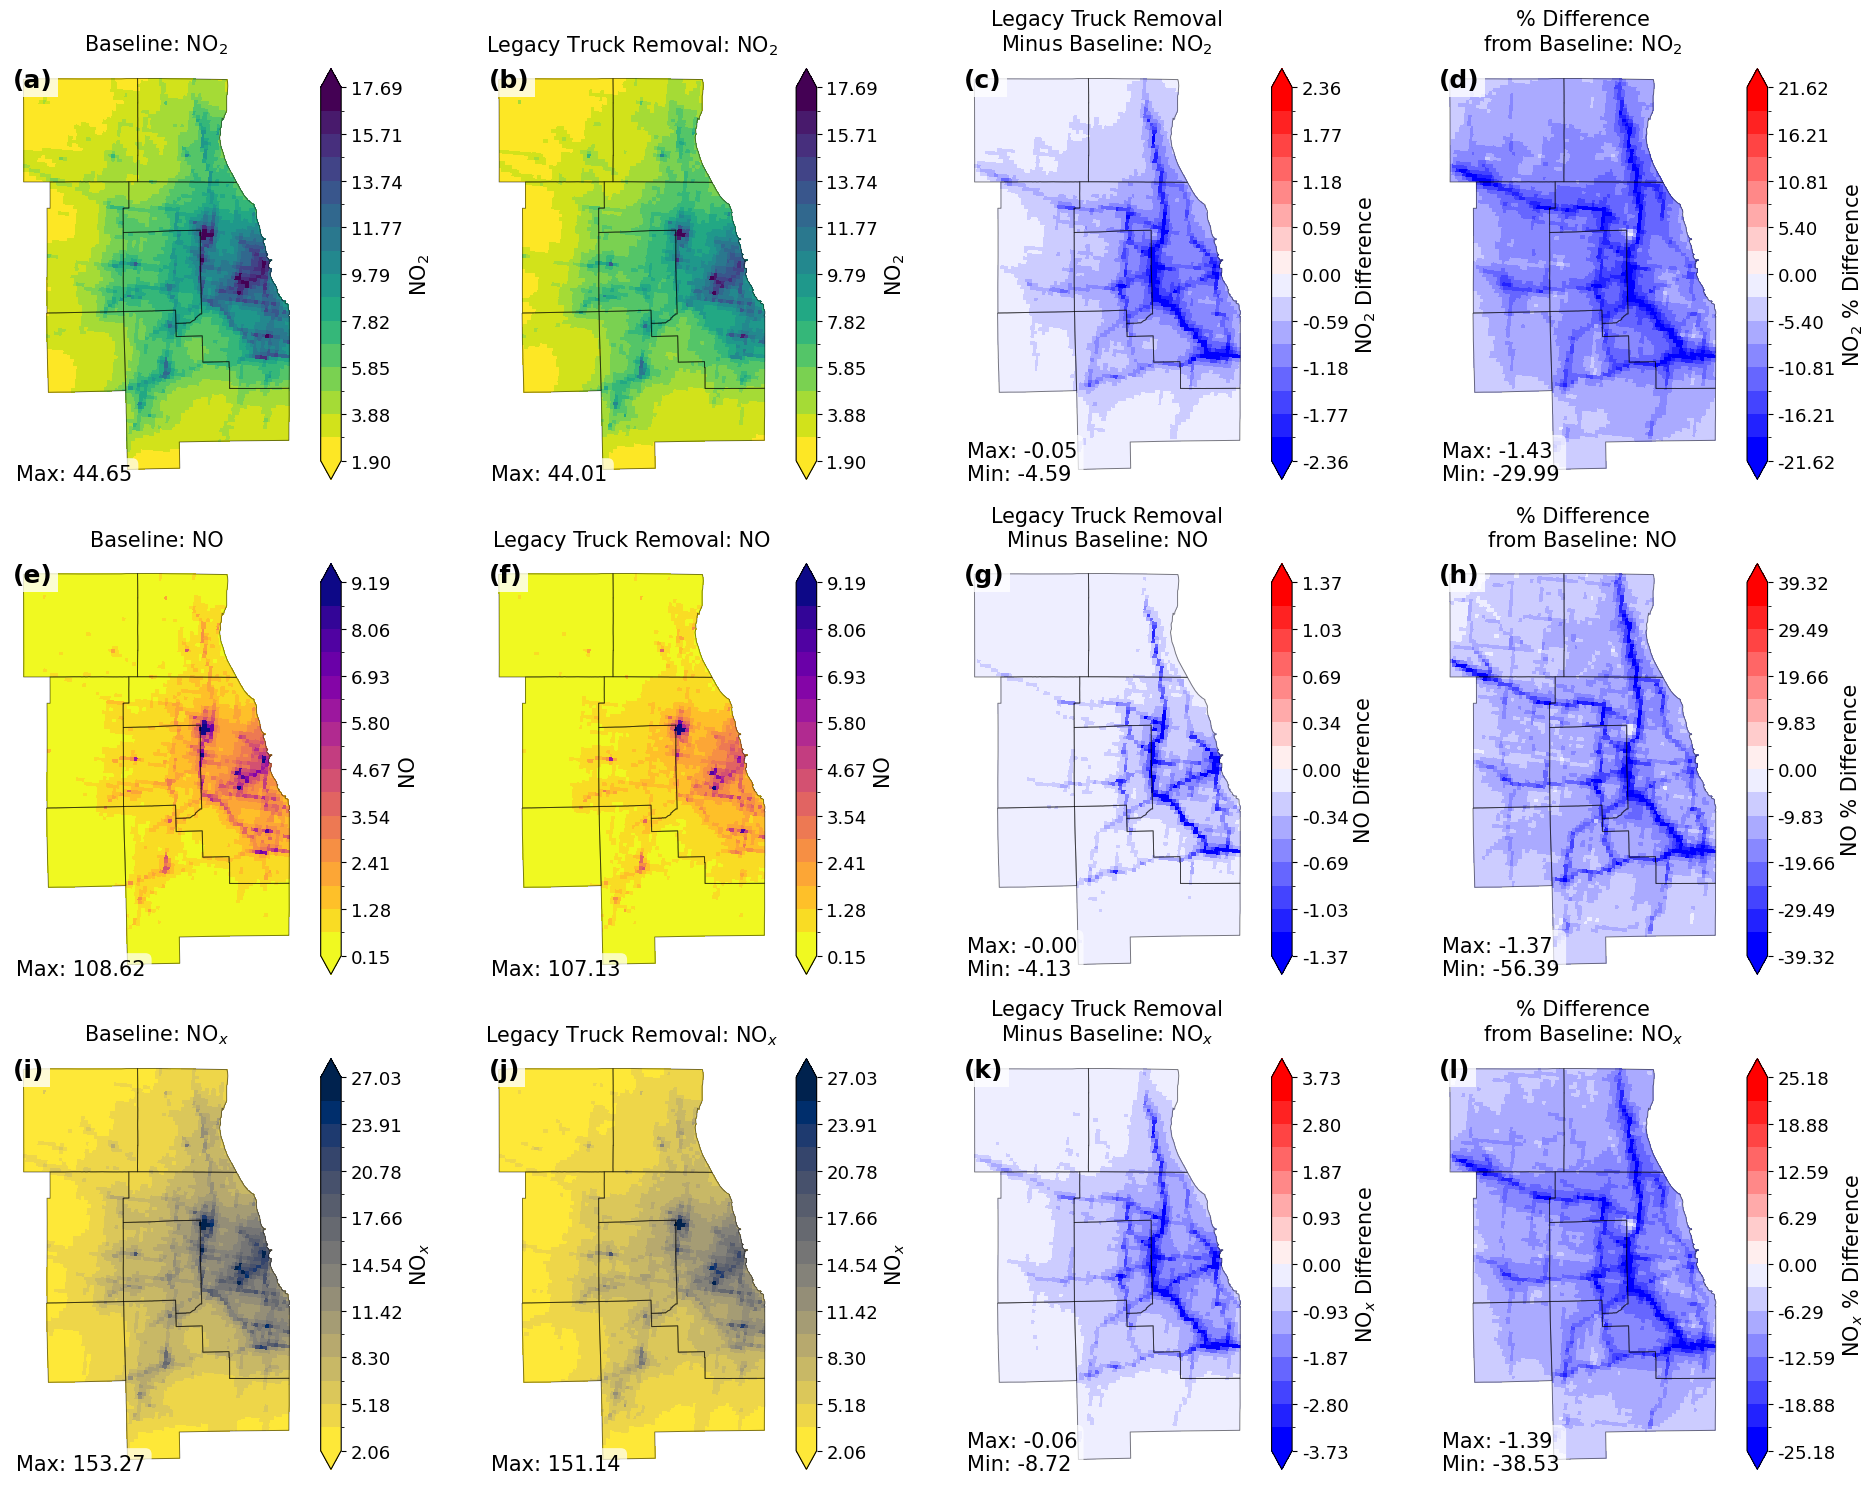

In [19]:
# plot annual baseline and legacy truck removal NOx concentrations
N_BINS = 16
pollutants = ["NO2", "NO", "NOX"]
scenario_names = ["Baseline", "Legacy Truck Removal", "Legacy Truck Removal\nMinus Baseline", "% Difference\nfrom Baseline"]

# set the color scale and labels used for each pollutant
plot_config = {
    "NO2": {"cmap": "viridis_r", "title": "NO$_2$", "label": "NO$_2$", "column": "NO2"},
    "NO": {"cmap": "plasma_r", "title": "NO", "label": "NO", "column": "NO"},
    "NOX": {"cmap": "cividis_r", "title": "NO$_x$", "label": "NO$_x$", "column": "NOX"},
}

# use the baseline and legacy truck removal ACONC files for each pollutant
annual_gdfs_by_pol = {pol: {"reference": cmap_base_aconc, "scenario": cmap_zeropre2010s_aconc} for pol in pollutants}


# make a discrete color scale using the requested limits
def make_discrete_style(vmin, vmax, cmap_name):
    if np.isclose(vmin, vmax):
        vmax = vmin + 1e-6
    bounds = np.linspace(vmin, vmax, N_BINS + 1)
    cmap = ListedColormap(plt.colormaps[cmap_name](np.linspace(0, 1, N_BINS)))
    return {"bounds": bounds, "cmap": cmap, "norm": BoundaryNorm(bounds, cmap.N)}


def plot_annual_nox_removal():

    plot_data = {}
    plot_styles = {}

    # calculate the baseline, removal, absolute difference, and percent difference
    for pol in pollutants:
        cfg = plot_config[pol]
        col = cfg["column"]
        reference_gdf = annual_gdfs_by_pol[pol]["reference"]
        scenario_gdf = annual_gdfs_by_pol[pol]["scenario"]

        reference_vals = reference_gdf[col].astype(float).to_numpy()
        scenario_vals = scenario_gdf[col].astype(float).to_numpy()
        diff_vals = scenario_vals - reference_vals

        pct_vals = np.full(diff_vals.shape, np.nan, dtype=float)
        np.divide(diff_vals, reference_vals, out=pct_vals, where=reference_vals != 0)
        pct_vals *= 100

        # use the same absolute color scale for the baseline and removal panels
        absolute_vals = np.concatenate([reference_vals[np.isfinite(reference_vals)], scenario_vals[np.isfinite(scenario_vals)]])
        absolute_min, absolute_max = np.quantile(absolute_vals, [0.001, 0.999])

        # center the difference color scales around zero
        diff_lim = max(np.quantile(np.abs(diff_vals[np.isfinite(diff_vals)]), 0.99), 1e-6)
        pct_lim = max(np.quantile(np.abs(pct_vals[np.isfinite(pct_vals)]), 0.99), 1e-6)

        plot_styles[pol] = {
            "absolute": make_discrete_style(absolute_min, absolute_max, cfg["cmap"]),
            "difference": make_discrete_style(-diff_lim, diff_lim, "bwr"),
            "percent": make_discrete_style(-pct_lim, pct_lim, "bwr"),
        }

        plot_data[pol] = {
            "values": [reference_vals, scenario_vals, diff_vals, pct_vals],
            "sources": [reference_gdf, scenario_gdf, scenario_gdf, scenario_gdf],
        }

    # make one row for each pollutant and one column for each comparison
    fig, axs = plt.subplots(len(pollutants), len(scenario_names), figsize=(20, 15), subplot_kw={"projection": ccrs.PlateCarree()})

    for i, pol in enumerate(pollutants):
        cfg = plot_config[pol]
        values = plot_data[pol]["values"]
        sources = plot_data[pol]["sources"]

        for j, scenario_name in enumerate(scenario_names):
            ax = axs[i, j]
            style_name = "absolute" if j < 2 else "difference" if j == 2 else "percent"
            style = plot_styles[pol][style_name]

            # copy the geometry and add the values plotted in this panel
            gdf = sources[j].copy()
            gdf[pol] = values[j]

            # plot the gridded concentrations and county boundaries
            gdf.plot(column=pol, ax=ax, cmap=style["cmap"], norm=style["norm"], edgecolor="none", antialiased=False)
            cmap_cty.boundary.plot(ax=ax, color="black", linewidth=0.7, alpha=0.5)

            ax.set_title(f"{scenario_name}: {cfg['title']}", fontsize=15)
            ax.set_axis_off()

            # add the panel label in the upper-left corner
            panel_label = f"({chr(97 + i * len(scenario_names) + j)})"
            ax.text(0.01, 0.98, panel_label, transform=ax.transAxes, ha="left", va="top", fontsize=18, fontweight="bold", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"})

            # add the color bar for each panel
            sm = plt.cm.ScalarMappable(norm=style["norm"], cmap=style["cmap"])
            sm.set_array([])
            cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04, boundaries=style["bounds"], ticks=style["bounds"][::2], extend="both")
            cbar.ax.tick_params(labelsize=13)
            cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

            if j == 2:
                cbar.set_label(f"{cfg['label']} Difference", fontsize=15)
            elif j == 3:
                cbar.set_label(f"{cfg['label']} % Difference", fontsize=15)
            else:
                cbar.set_label(cfg["label"], fontsize=15)

            # show the maximum for concentrations and the range for changes
            finite_vals = values[j][np.isfinite(values[j])]
            summary_text = f"Max: {np.nanmax(finite_vals):.2f}" if j < 2 else f"Max: {np.nanmax(finite_vals):.2f}\nMin: {np.nanmin(finite_vals):.2f}"
            ax.text(0.02, 0.02, summary_text, transform=ax.transAxes, ha="left", va="bottom", fontsize=15, bbox={"facecolor": "white", "alpha": 0.7, "boxstyle": "round", "linewidth": 0})

    plt.tight_layout()
    #plt.savefig("Fig_Annualized_NO2_NO_NOX_ZeroPre2010s.png", dpi=500, bbox_inches="tight")
    plt.show()

plot_annual_nox_removal()

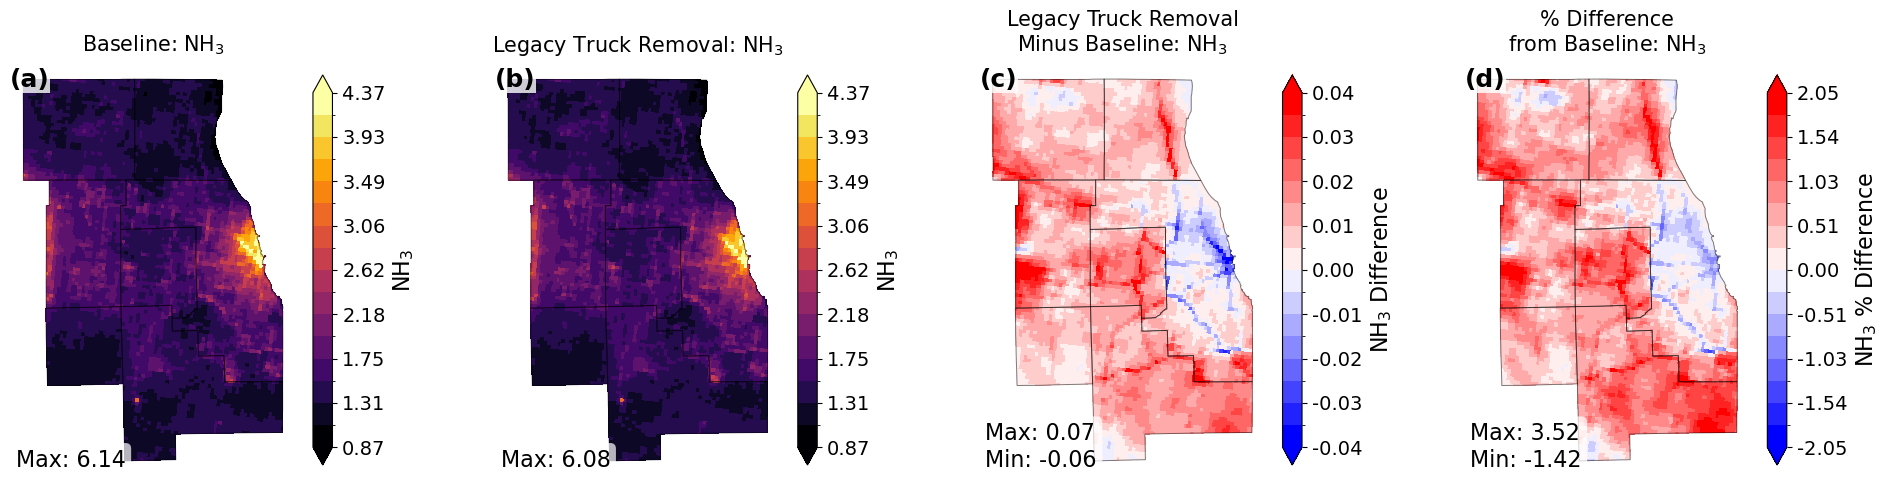

In [20]:
# plot annual baseline and legacy truck removal NH3 concentrations
N_BINS = 16
pollutant = "NH3"
scenario_names = ["Baseline", "Legacy Truck Removal", "Legacy Truck Removal\nMinus Baseline", "% Difference\nfrom Baseline"]
plot_config = {"cmap": "inferno", "title": "NH$_3$", "label": "NH$_3$", "column": "NH3"}


# make a discrete color scale using the requested limits
def make_discrete_style(vmin, vmax, cmap_name):
    if np.isclose(vmin, vmax):
        vmax = vmin + 1e-6
    bounds = np.linspace(vmin, vmax, N_BINS + 1)
    cmap = ListedColormap(plt.colormaps[cmap_name](np.linspace(0, 1, N_BINS)))
    return {"bounds": bounds, "cmap": cmap, "norm": BoundaryNorm(bounds, cmap.N)}


def plot_annual_nh3_removal():

    col = plot_config["column"]
    reference_gdf = cmap_base_aconc
    scenario_gdf = cmap_zeropre2010s_aconc

    # calculate the baseline, removal, absolute difference, and percent difference
    reference_vals = reference_gdf[col].astype(float).to_numpy()
    scenario_vals = scenario_gdf[col].astype(float).to_numpy()
    diff_vals = scenario_vals - reference_vals

    pct_vals = np.full(diff_vals.shape, np.nan, dtype=float)
    np.divide(diff_vals, reference_vals, out=pct_vals, where=reference_vals != 0)
    pct_vals *= 100

    # use the same absolute color scale for the baseline and removal panels
    absolute_vals = np.concatenate([reference_vals[np.isfinite(reference_vals)], scenario_vals[np.isfinite(scenario_vals)]])
    absolute_min, absolute_max = np.quantile(absolute_vals, [0.001, 0.999])

    # center the difference color scales around zero
    diff_lim = max(np.quantile(np.abs(diff_vals[np.isfinite(diff_vals)]), 0.99), 1e-6)
    pct_lim = max(np.quantile(np.abs(pct_vals[np.isfinite(pct_vals)]), 0.99), 1e-6)

    absolute_style = make_discrete_style(absolute_min, absolute_max, plot_config["cmap"])
    difference_style = make_discrete_style(-diff_lim, diff_lim, "bwr")
    percent_style = make_discrete_style(-pct_lim, pct_lim, "bwr")

    plot_values = [reference_vals, scenario_vals, diff_vals, pct_vals]
    plot_sources = [reference_gdf, scenario_gdf, scenario_gdf, scenario_gdf]
    plot_styles = [absolute_style, absolute_style, difference_style, percent_style]

    # make one panel for each comparison
    fig, axs = plt.subplots(1, 4, figsize=(20, 5), subplot_kw={"projection": ccrs.PlateCarree()})

    for j, scenario_name in enumerate(scenario_names):
        ax = axs[j]
        style = plot_styles[j]

        # copy the geometry and add the values plotted in this panel
        gdf = plot_sources[j].copy()
        gdf[pollutant] = plot_values[j]

        # plot the gridded concentrations and county boundaries
        gdf.plot(column=pollutant, ax=ax, cmap=style["cmap"], norm=style["norm"], edgecolor="none", antialiased=False)
        cmap_cty.boundary.plot(ax=ax, color="black", alpha=0.5, linewidth=0.7)

        ax.set_title(f"{scenario_name}: {plot_config['title']}", fontsize=15)
        ax.set_axis_off()

        # add the panel label in the upper-left corner
        ax.text(0.001, 0.98, f"({chr(97 + j)})", transform=ax.transAxes, ha="left", va="top", fontsize=18, fontweight="bold", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 0.2})

        # add the color bar for each panel
        sm = plt.cm.ScalarMappable(norm=style["norm"], cmap=style["cmap"])
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04, boundaries=style["bounds"], ticks=style["bounds"][::2], spacing="proportional", extend="both")
        cbar.ax.tick_params(labelsize=14)
        cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

        if j == 2:
            cbar.set_label(f"{plot_config['label']} Difference", fontsize=16)
        elif j == 3:
            cbar.set_label(f"{plot_config['label']} % Difference", fontsize=16)
        else:
            cbar.set_label(plot_config["label"], fontsize=16)

        # show the maximum for concentrations and the range for changes
        finite_vals = plot_values[j][np.isfinite(plot_values[j])]
        annot_text = f"Max: {np.nanmax(finite_vals):.2f}" if j < 2 else f"Max: {np.nanmax(finite_vals):.2f}\nMin: {np.nanmin(finite_vals):.2f}"
        ax.text(0.02, 0.02, annot_text, transform=ax.transAxes, ha="left", va="bottom", fontsize=16, color="black", bbox={"facecolor": "white", "alpha": 0.7, "boxstyle": "round,pad=0.25", "linewidth": 0})

    plt.tight_layout()
    #plt.savefig("Fig_Annualized_Default_zeropre2010s_NH3_2023.png", dpi=500, bbox_inches="tight")
    plt.show()


plot_annual_nh3_removal()

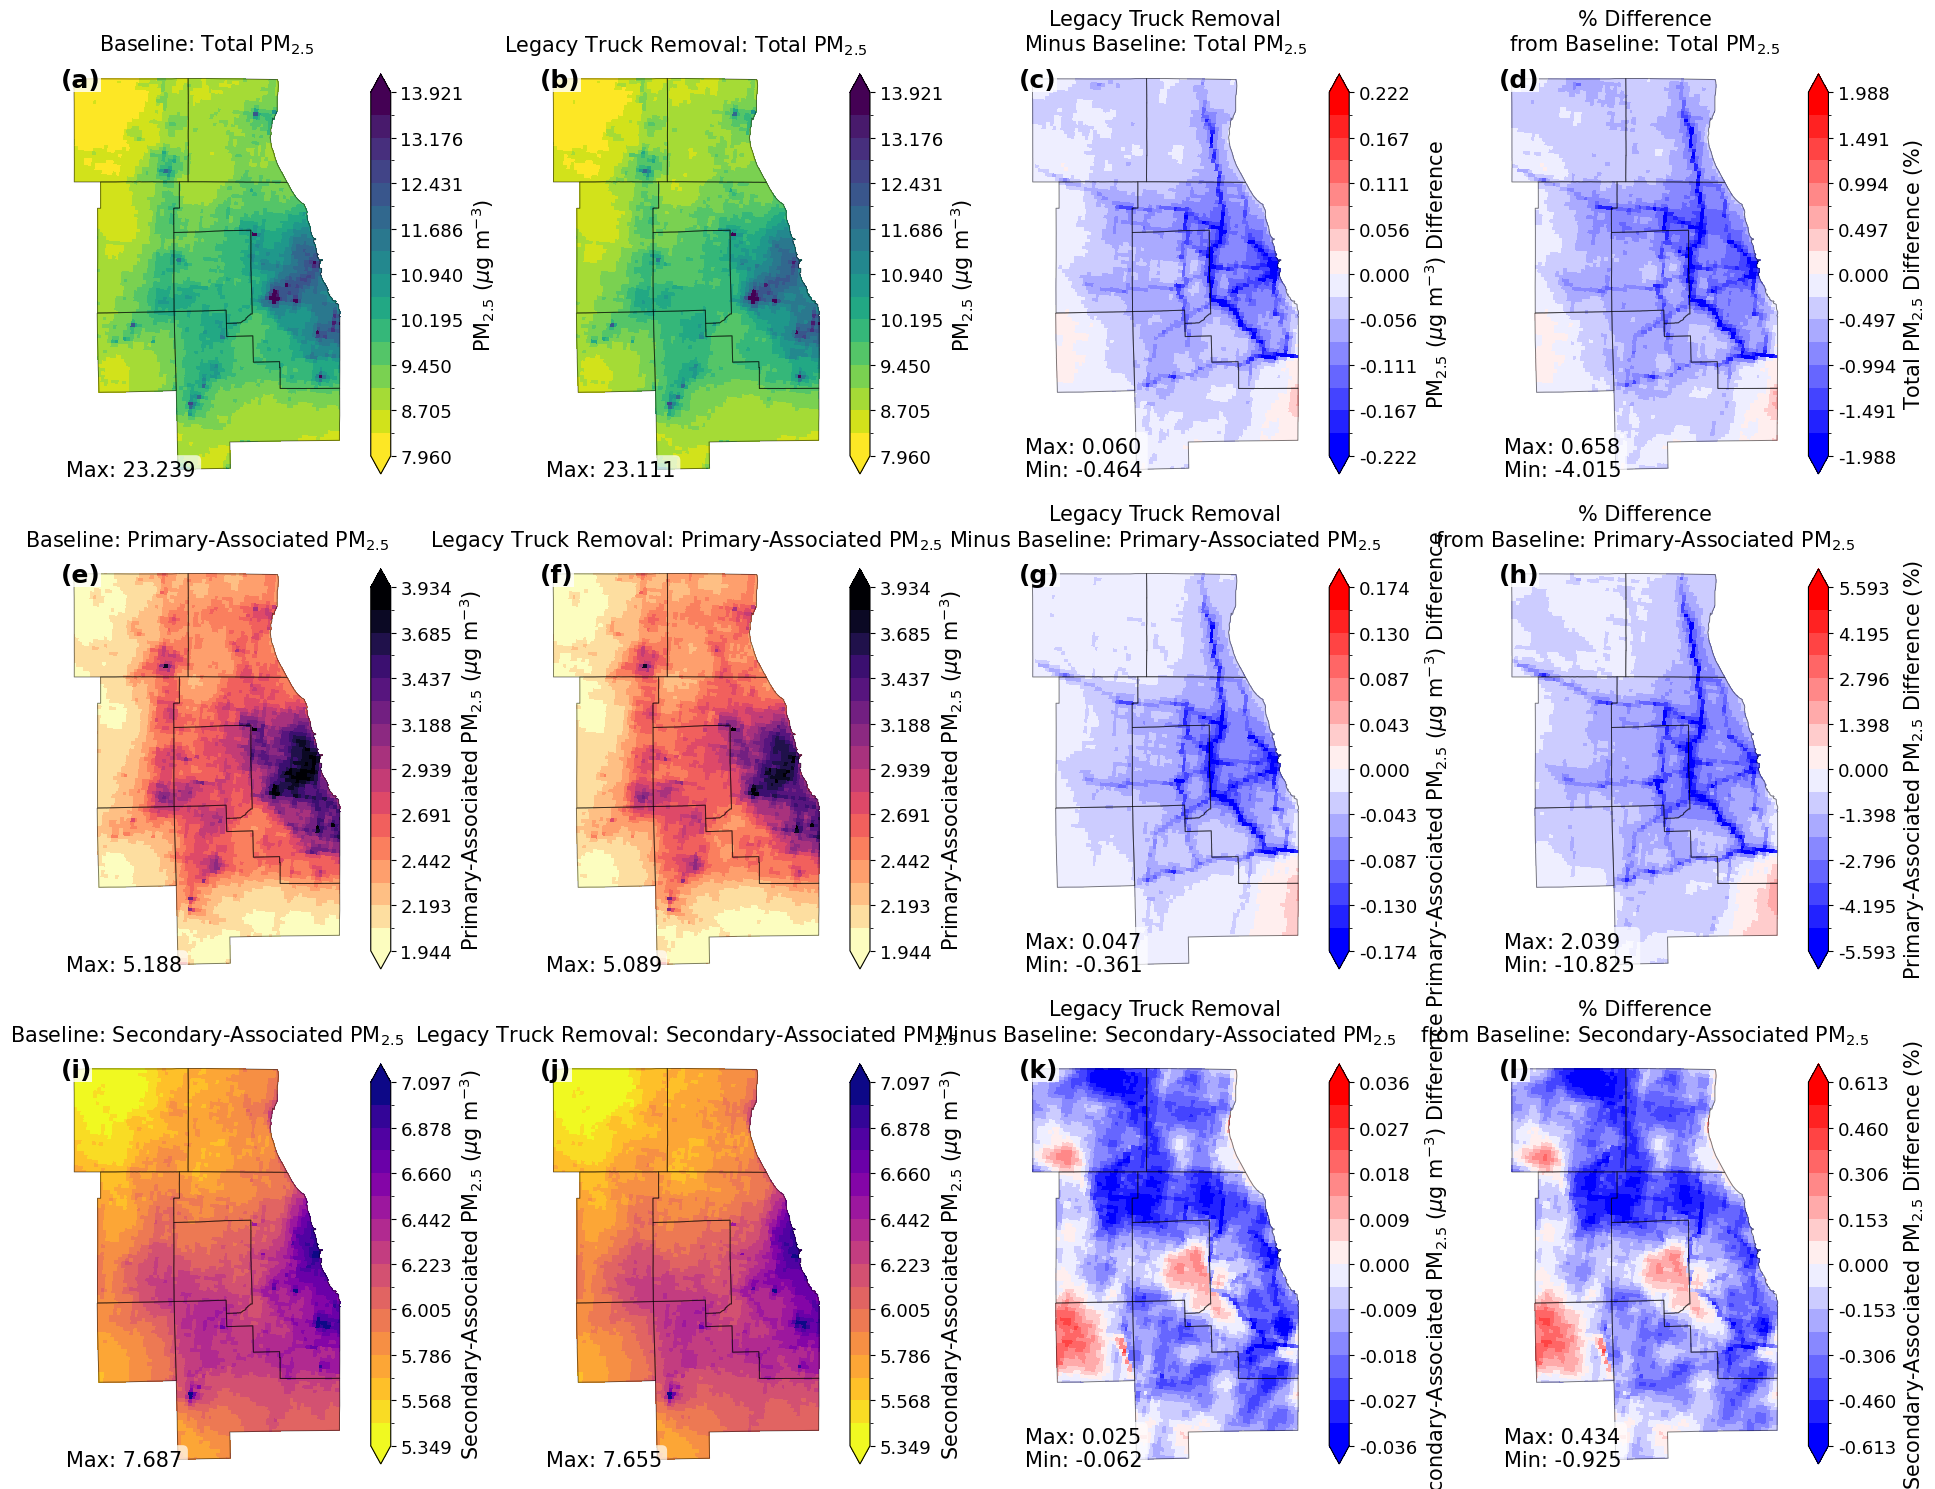

In [21]:
# calculate the primary- and secondary-associated fine-mode PM components
for gdf in [cmap_base_aconc, cmap_zeropre2010s_aconc]:
    gdf["Primary_PM25"] = gdf[PRIMARY_PM].sum(axis=1)
    gdf["Secondary_PM25"] = gdf[SECONDARY_PM].sum(axis=1)

# set the labels and color scales used for each PM group
pm25_groups = {
    "Primary_PM25": {"title": "Primary-Associated PM$_{2.5}$", "label": "Primary-Associated PM$_{2.5}$ ($\\mu$g m$^{-3}$)", "cmap_name": "magma_r"},
    "Secondary_PM25": {"title": "Secondary-Associated PM$_{2.5}$", "label": "Secondary-Associated PM$_{2.5}$ ($\\mu$g m$^{-3}$)", "cmap_name": "plasma_r"},
}

N_BINS = 16
scenario_names = ["Baseline", "Legacy Truck Removal", "Legacy Truck Removal\nMinus Baseline", "% Difference\nfrom Baseline"]


# make a discrete color scale using the requested limits
def make_discrete_style(vmin, vmax, cmap_name):
    if np.isclose(vmin, vmax):
        vmax = vmin + 1e-6
    bounds = np.linspace(vmin, vmax, N_BINS + 1)
    cmap = ListedColormap(plt.colormaps[cmap_name](np.linspace(0, 1, N_BINS)))
    return {"bounds": bounds, "cmap": cmap, "norm": BoundaryNorm(bounds, cmap.N)}


def plot_primary_secondary_pm25_removal():

    # add total PM2.5 above the primary- and secondary-associated groups
    plot_groups = {"PM25_TOT": {"cmap_name": "viridis_r", "title": "Total PM$_{2.5}$", "label": "PM$_{2.5}$ ($\\mu$g m$^{-3}$)"}, **pm25_groups}
    plot_data = {}
    plot_styles = {}

    for pm_group, cfg in plot_groups.items():

        # calculate the baseline, removal, absolute difference, and percent difference
        base_vals = cmap_base_aconc[pm_group].astype(float).to_numpy()
        removal_vals = cmap_zeropre2010s_aconc[pm_group].astype(float).to_numpy()
        diff_vals = removal_vals - base_vals

        pct_vals = np.full(diff_vals.shape, np.nan, dtype=float)
        np.divide(diff_vals, base_vals, out=pct_vals, where=base_vals != 0)
        pct_vals *= 100

        # use the same absolute color scale for the baseline and removal panels
        absolute_vals = np.concatenate([base_vals[np.isfinite(base_vals)], removal_vals[np.isfinite(removal_vals)]])
        absolute_min, absolute_max = np.quantile(absolute_vals, [0.001, 0.999])

        # center the difference color scales around zero
        diff_lim = max(np.quantile(np.abs(diff_vals[np.isfinite(diff_vals)]), 0.99), 1e-6)
        pct_lim = max(np.quantile(np.abs(pct_vals[np.isfinite(pct_vals)]), 0.99), 1e-6)

        plot_styles[pm_group] = {
            "absolute": make_discrete_style(absolute_min, absolute_max, cfg["cmap_name"]),
            "difference": make_discrete_style(-diff_lim, diff_lim, "bwr"),
            "percent": make_discrete_style(-pct_lim, pct_lim, "bwr"),
        }

        plot_data[pm_group] = {
            "values": [base_vals, removal_vals, diff_vals, pct_vals],
            "sources": [cmap_base_aconc, cmap_zeropre2010s_aconc, cmap_zeropre2010s_aconc, cmap_zeropre2010s_aconc],
        }

    # make one row for each PM group and one column for each comparison
    fig, axs = plt.subplots(len(plot_groups), len(scenario_names), figsize=(20, 5 * len(plot_groups)), subplot_kw={"projection": ccrs.PlateCarree()})

    # add a title when needed
    # fig.suptitle("Annualized 2023 Total, Primary-Associated, and Secondary-Associated PM$_{2.5}$", fontsize=24, y=1.01)

    for i, (pm_group, cfg) in enumerate(plot_groups.items()):
        values = plot_data[pm_group]["values"]
        sources = plot_data[pm_group]["sources"]

        for j, scenario_name in enumerate(scenario_names):
            ax = axs[i, j]
            style_name = "absolute" if j < 2 else "difference" if j == 2 else "percent"
            style = plot_styles[pm_group][style_name]

            # copy the geometry and add the values plotted in this panel
            gdf = sources[j].copy()
            gdf[pm_group] = values[j]

            # plot the spatial field and county boundaries
            gdf.plot(column=pm_group, ax=ax, cmap=style["cmap"], norm=style["norm"], edgecolor="none", antialiased=False)
            cmap_cty.boundary.plot(ax=ax, color="black", alpha=0.5, linewidth=0.7)

            ax.set_title(f"{scenario_name}: {cfg['title']}", fontsize=15)
            ax.set_axis_off()

            # add the panel label in the upper-left corner
            panel_label = f"({chr(97 + i * len(scenario_names) + j)})"
            ax.text(0.001, 0.98, panel_label, transform=ax.transAxes, ha="left", va="top", fontsize=18, fontweight="bold", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 0.2}, zorder=10)

            # add the color bar for each panel
            sm = plt.cm.ScalarMappable(norm=style["norm"], cmap=style["cmap"])
            sm.set_array([])
            cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04, boundaries=style["bounds"], ticks=style["bounds"][::2], spacing="proportional", extend="both")
            cbar.ax.tick_params(labelsize=13)
            cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.3f"))

            if j == 2:
                cbar.set_label(f"{cfg['label']} Difference", fontsize=15)
            elif j == 3:
                cbar.set_label(f"{cfg['title']} Difference (%)", fontsize=15)
            else:
                cbar.set_label(cfg["label"], fontsize=15)

            # show the maximum for concentrations and the range for changes
            finite_vals = values[j][np.isfinite(values[j])]
            annot_text = f"Max: {np.nanmax(finite_vals):.3f}" if j < 2 else f"Max: {np.nanmax(finite_vals):.3f}\nMin: {np.nanmin(finite_vals):.3f}"
            ax.text(0.02, 0.02, annot_text, transform=ax.transAxes, ha="left", va="bottom", fontsize=15, color="black", bbox={"facecolor": "white", "alpha": 0.7, "boxstyle": "round,pad=0.25", "linewidth": 0}, zorder=10)

    plt.tight_layout()
   #plt.savefig("Fig_Annualized_Default_zeropre2010s_TotalPrimarySecondaryPM25_2023.png", dpi=500, bbox_inches="tight")
    plt.show()

plot_primary_secondary_pm25_removal()

<h1> Plot Fractional Reduction of Legacy Truck Pollutant via Accelerated Renewal

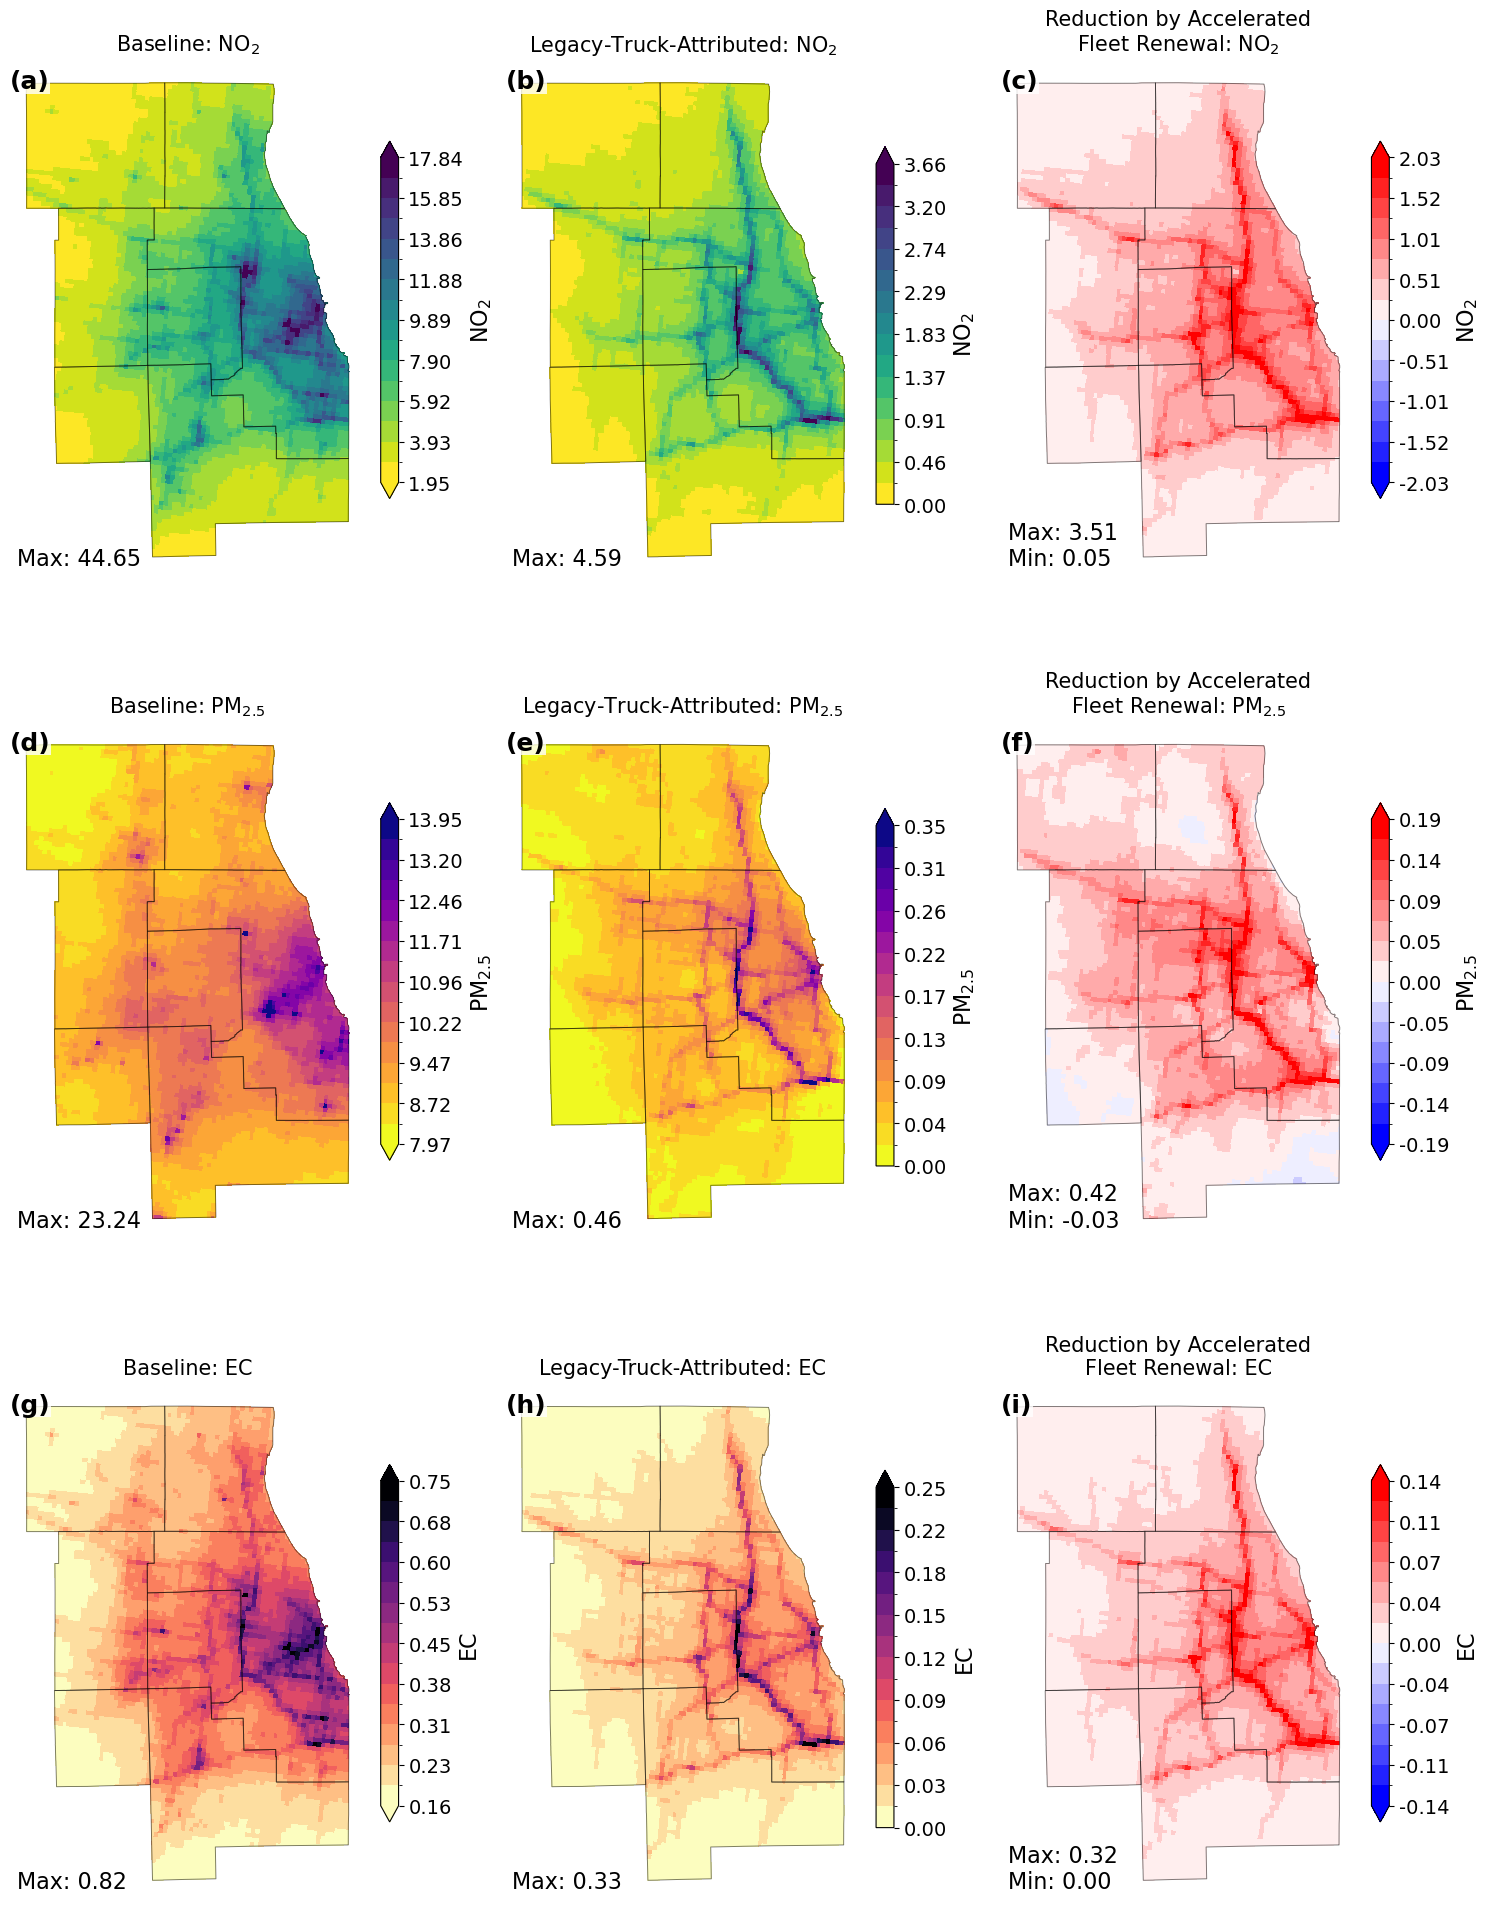

In [25]:
# ------------------------------------------------------------
# Plot:
#   1. Baseline concentration
#   2. Legacy-truck-attributed concentration (Baseline - Legacy Truck Sims)
#   3. Concentration removed by accelerated fleet renewal (Renewal - Baseline)
# ------------------------------------------------------------

N_BINS = 16

pollutants = [
    "NO2",
    "PM25_TOT",
    "PM25_EC",
#    "O3",
]

scenario_names = [
    "Baseline",
    "Legacy-Truck-Attributed",
    "Reduction by Accelerated\nFleet Renewal",
]

# ------------------------------------------------------------
# Plot configuration
# ------------------------------------------------------------
plot_config = {
    "NO2": {
        "cmap_name": "viridis_r",
        "title": "NO$_2$",
        "label": "NO$_2$",
        "column": "NO2",
    },

    "PM25_TOT": {
        "cmap_name": "plasma_r",
        "title": "PM$_{2.5}$",
        "label": "PM$_{2.5}$",
        "column": "PM25_TOT",
    },

    "PM25_EC": {
        "cmap_name": "magma_r",
        "title": "EC",
        "label": "EC",
        "column": "PM25_EC",
    },

#     "O3": {
#         "cmap_name": "cividis_r",
#         "title": "MDA8 O$_3$",
#         "label": "MDA8 O$_3$",
#         "column": "O3",
#     },
}

# ------------------------------------------------------------
# GeoDataFrames associated with each pollutant/scenario
# ------------------------------------------------------------
annual_gdfs_by_pol = {
    "NO2": {
        "baseline": cmap_base_aconc,
        "renewal": cmap_renewal_aconc,
        "zero_legacy": cmap_zeropre2010s_aconc,
    },

    "PM25_TOT": {
        "baseline": cmap_base_aconc,
        "renewal": cmap_renewal_aconc,
        "zero_legacy": cmap_zeropre2010s_aconc,
    },

    "PM25_EC": {
        "baseline": cmap_base_aconc,
        "renewal": cmap_renewal_aconc,
        "zero_legacy": cmap_zeropre2010s_aconc,
    },

#     "O3": {
#         "baseline": cmap_base_o3,
#         "renewal": cmap_renewal_o3,
#         "zero_legacy": cmap_zeropre2010s_o3,
#     },
}


def plot_legacy_reduction():

    # Store plotting styles separately for every pollutant
    baseline_styles = {}
    legacy_styles = {}
    renewal_styles = {}

    # Store the plotting GeoDataFrames
    scenario_gdfs_by_pol = {}

    # Store the unmodified values for annotations
    annotation_values = {}

    # ========================================================
    # Calculate plotting fields and color scales
    # ========================================================
    for pol in pollutants:

        cfg = plot_config[pol]
        col = cfg["column"]

        baseline_gdf = annual_gdfs_by_pol[pol]["baseline"]
        renewal_gdf = annual_gdfs_by_pol[pol]["renewal"]
        zero_legacy_gdf = annual_gdfs_by_pol[pol]["zero_legacy"]

        # ----------------------------------------------------
        # Extract concentration values
        # ----------------------------------------------------
        baseline_vals = baseline_gdf[col].astype(float)
        renewal_vals = renewal_gdf[col].astype(float)
        zero_legacy_vals = zero_legacy_gdf[col].astype(float)

        # Legacy-truck-attributed concentration:
        #
        # Baseline minus the scenario in which all pre-2010
        # trucks are removed.
        legacy_attributed = (
            baseline_vals
            - zero_legacy_vals
        )

        # Concentration removed by accelerated renewal:
        #
        # Baseline minus accelerated-renewal scenario.
        renewal_removed = (
            baseline_vals
            - renewal_vals
        )

        # Column 2 is explicitly plotted from zero upward.
        #
        # Negative values are clipped to zero for visualization.
        # The original values are retained separately for the
        # maximum/minimum annotation.
        legacy_attributed_plot = legacy_attributed.clip(lower=0)

        # ----------------------------------------------------
        # Construct plotting GeoDataFrames
        # ----------------------------------------------------
        plot_baseline = baseline_gdf.copy()
        plot_legacy = baseline_gdf.copy()
        plot_renewal_removed = baseline_gdf.copy()

        plot_baseline[pol] = baseline_vals
        plot_legacy[pol] = legacy_attributed_plot
        plot_renewal_removed[pol] = renewal_removed

        scenario_gdfs_by_pol[pol] = {
            scenario_names[0]: plot_baseline,
            scenario_names[1]: plot_legacy,
            scenario_names[2]: plot_renewal_removed,
        }

        annotation_values[pol] = {
            scenario_names[0]: baseline_vals,
            scenario_names[1]: legacy_attributed,
            scenario_names[2]: renewal_removed,
        }

        # ====================================================
        # Column 1: baseline concentration scale
        # ====================================================
        finite_baseline = baseline_vals.to_numpy()
        finite_baseline = finite_baseline[
            np.isfinite(finite_baseline)
        ]

        baseline_vmin = np.quantile(
            finite_baseline,
            0.001,
        )

        baseline_vmax = np.quantile(
            finite_baseline,
            0.999,
        )

        if np.isclose(baseline_vmin, baseline_vmax):
            baseline_vmax = baseline_vmin + 1e-6

        baseline_cmap = ListedColormap(
            plt.colormaps[cfg["cmap_name"]](
                np.linspace(
                    0,
                    1,
                    N_BINS,
                )
            )
        )

        baseline_bounds = np.linspace(
            baseline_vmin,
            baseline_vmax,
            N_BINS + 1,
        )

        baseline_styles[pol] = {
            "cmap": baseline_cmap,
            "bounds": baseline_bounds,
            "norm": BoundaryNorm(
                baseline_bounds,
                baseline_cmap.N,
            ),
            "extend": "both",
        }

        # ====================================================
        # Column 2: legacy-truck-attributed concentration
        #
        # Uses the same colormap as the baseline panel, but
        # its own scale beginning at zero.
        # ====================================================
        finite_legacy = legacy_attributed_plot.to_numpy()
        finite_legacy = finite_legacy[
            np.isfinite(finite_legacy)
        ]

#         legacy_vmax = np.quantile(
#             finite_legacy,leg
#             0.999,
#         )
        if pol == "O3":
            legacy_vmax = 0.005      # or 0.015 or 0.01
        else:
            legacy_vmax = np.quantile(
                finite_legacy,
                0.999,
            )
        if np.isclose(legacy_vmax, 0):
            legacy_vmax = 1e-6

        legacy_bounds = np.linspace(
            0,
            legacy_vmax,
            N_BINS + 1,
        )

        legacy_cmap = ListedColormap(
            plt.colormaps[cfg["cmap_name"]](
                np.linspace(
                    0,
                    1,
                    N_BINS,
                )
            )
        )

        legacy_styles[pol] = {
            "cmap": legacy_cmap,
            "bounds": legacy_bounds,
            "norm": BoundaryNorm(
                legacy_bounds,
                legacy_cmap.N,
            ),
            "extend": "max",
        }

        # ====================================================
        # Column 3: concentration removed by renewal
        #
        # Uses a diverging scale centered at zero because
        # accelerated renewal may increase or decrease a
        # pollutant depending on atmospheric chemistry.
        # ====================================================
        finite_renewal = renewal_removed.to_numpy()
        finite_renewal = finite_renewal[
            np.isfinite(finite_renewal)
        ]

        renewal_limit = np.quantile(
            np.abs(finite_renewal),
            0.99,
        )

        if np.isclose(renewal_limit, 0):
            renewal_limit = 1e-6

        renewal_bounds = np.linspace(
            -renewal_limit,
            renewal_limit,
            N_BINS + 1,
        )

        renewal_cmap = ListedColormap(
            plt.colormaps["bwr"](
                np.linspace(
                    0,
                    1,
                    N_BINS,
                )
            )
        )

        renewal_styles[pol] = {
            "cmap": renewal_cmap,
            "bounds": renewal_bounds,
            "norm": BoundaryNorm(
                renewal_bounds,
                renewal_cmap.N,
            ),
            "extend": "both",
        }

    # ========================================================
    # Create figure
    # ========================================================
    fig, axs = plt.subplots(
        nrows=len(pollutants),
        ncols=len(scenario_names),
        figsize=(15, 20),
        subplot_kw={
            "projection": ccrs.PlateCarree(),
        },
    )

    # ========================================================
    # Plot every pollutant and scenario
    # ========================================================
    for i, pol in enumerate(pollutants):

        for j, scenario_name in enumerate(scenario_names):

            ax = axs[i, j]

            gdf = scenario_gdfs_by_pol[pol][
                scenario_name
            ]

            # Panel labels:
            # (a), (b), (c), ...
            panel_number = (
                i * len(scenario_names)
                + j
            )

            panel_label = (
                f"({chr(97 + panel_number)})"
            )

            ax.text(
                0.001,
                0.98,
                panel_label,
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=18,
                fontweight="bold",
                bbox={
                    "facecolor": "white",
                    "alpha": 0.8,
                    "edgecolor": "none",
                    "pad": 0.2,
                },
                zorder=10,
            )

            # ------------------------------------------------
            # Select the appropriate plotting style
            # ------------------------------------------------
            if j == 0:
                style = baseline_styles[pol]

            elif j == 1:
                style = legacy_styles[pol]

            else:
                style = renewal_styles[pol]

            cmap_disc = style["cmap"]
            norm = style["norm"]
            bounds = style["bounds"]
            extend = style["extend"]

            # ------------------------------------------------
            # Plot spatial field
            # ------------------------------------------------
            gdf.plot(
                column=pol,
                ax=ax,
                cmap=cmap_disc,
                norm=norm,
                edgecolor="none",
                antialiased=False,
            )

            # County boundaries
            cmap_cty.boundary.plot(
                ax=ax,
                color="black",
                alpha=0.5,
                linewidth=0.7,
            )

            ax.set_title(
                (
                    f"{scenario_name}: "
                    f"{plot_config[pol]['title']}"
                ),
                fontsize=15,
            )

            ax.set_axis_off()

            # ------------------------------------------------
            # Colorbar
            # ------------------------------------------------
            sm = plt.cm.ScalarMappable(
                norm=norm,
                cmap=cmap_disc,
            )

            sm.set_array([])

            cbar = fig.colorbar(
                sm,
                ax=ax,
                fraction=0.046,
                pad=0.04,
                boundaries=bounds,
                ticks=bounds[::2],
                spacing="proportional",
                extend=extend,
            )

            cbar.ax.tick_params(
                labelsize=14
            )

            cbar.ax.yaxis.set_major_formatter(
                FormatStrFormatter("%.2f")
            )

            cbar.set_label(
                plot_config[pol]["label"],
                fontsize=16,
            )

            # ------------------------------------------------
            # Maximum/minimum annotations
            #
            # Column 2 annotations use the original, unclipped
            # legacy-attributed values.
            # ------------------------------------------------
            vals = annotation_values[pol][
                scenario_name
            ].astype(float).to_numpy()

            vals = vals[
                np.isfinite(vals)
            ]

            if len(vals) > 0:

                vmax_panel = float(
                    np.nanmax(vals)
                )

                vmin_panel = float(
                    np.nanmin(vals)
                )

                # Baseline and legacy-attributed columns: show maximum only
                if j in [0, 1]:
                    annot_text = f"Max: {vmax_panel:.2f}"

                # Accelerated-renewal column: show maximum and minimum
                else:
                    annot_text = (
                        f"Max: {vmax_panel:.2f}\n"
                        f"Min: {vmin_panel:.2f}"
                    )

                ax.text(
                    0.02,
                    0.02,
                    annot_text,
                    transform=ax.transAxes,
                    ha="left",
                    va="bottom",
                    fontsize=16,
                    color="black",
                    bbox={
                        "facecolor": "white",
                        "alpha": 0.7,
                        "boxstyle": "round,pad=0.25",
                        "linewidth": 0,
                    },
                )

    plt.tight_layout()

    plt.savefig(
        "Fig_Annualized_Legacy_Truck_Contribution_and_Renewal_2023.png",
        dpi=500,
        bbox_inches="tight",
    )

    plt.show()


plot_legacy_reduction()

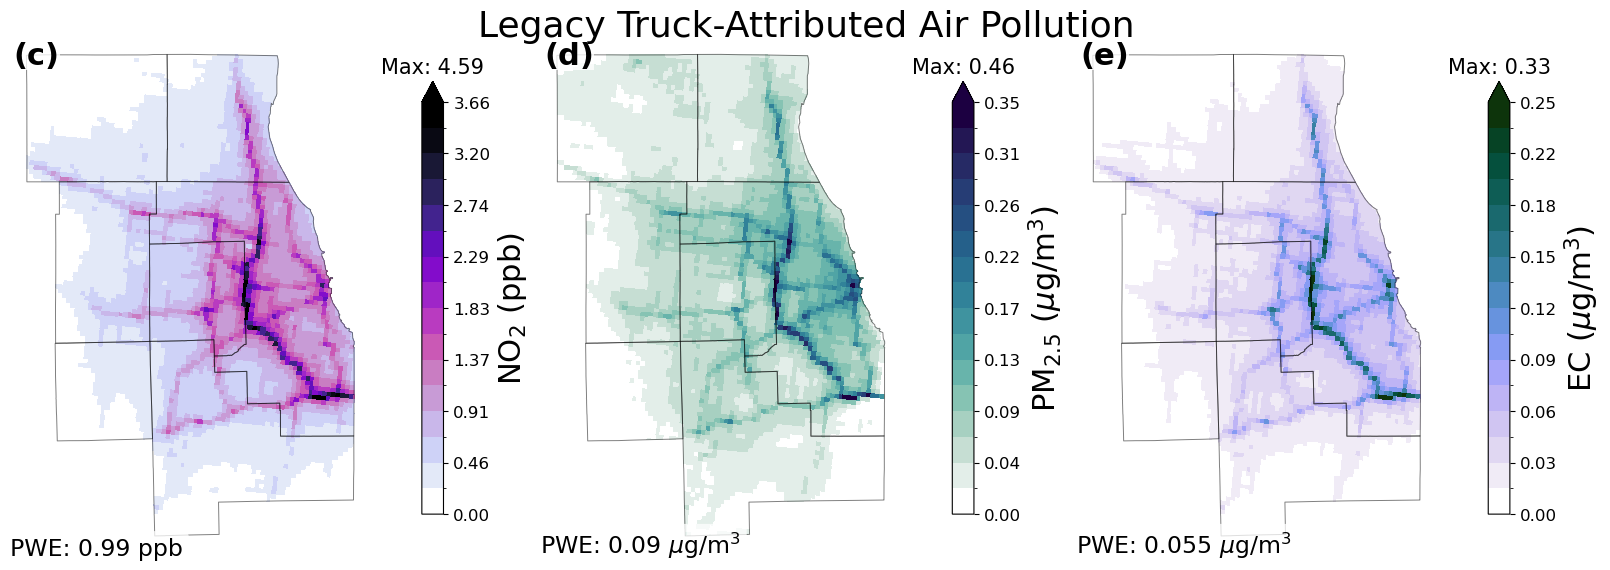

In [23]:

# plot the legacy-truck-attributed concentrations and population-weighted exposure
N_BINS = 16
pollutants = ["NO2", "PM25_TOT", "PM25_EC"]

# use baseline minus legacy truck removal to calculate the legacy contribution
pop_weighted_legacy = {"NO2": 0.985323, "PM25_TOT": 0.093222, "PM25_EC": 0.054826}

# set the color scale, labels, units, and rounding used for each pollutant
plot_config = {
    "NO2": {"cmap": cmr.gothic_r, "label": "NO$_2$ (ppb)", "column": "NO2", "pwe_unit": "ppb", "pwe_decimals": 2},
    "PM25_TOT": {"cmap": cmr.ocean_r, "label": "PM$_{2.5}$ ($\\mu$g/m$^{3}$)", "column": "PM25_TOT", "pwe_unit": "$\\mu$g/m$^3$", "pwe_decimals": 2},
    "PM25_EC": {"cmap": cmr.horizon_r, "label": "EC ($\\mu$g/m$^{3}$)", "column": "PM25_EC", "pwe_unit": "$\\mu$g/m$^3$", "pwe_decimals": 3},
}


def plot_legacy_truck_attributed():

    fig, axs = plt.subplots(1, 3, figsize=(16, 5.5), subplot_kw={"projection": ccrs.PlateCarree()}, constrained_layout=True)
    fig.suptitle("Legacy Truck-Attributed Air Pollution", fontsize=26, y=1.02)

    for i, pol in enumerate(pollutants):
        ax = axs[i]
        cfg = plot_config[pol]
        col = cfg["column"]

        # calculate the concentration attributed to legacy trucks
        baseline_vals = cmap_base_aconc[col].astype(float).to_numpy()
        zero_legacy_vals = cmap_zeropre2010s_aconc[col].astype(float).to_numpy()
        legacy_vals = baseline_vals - zero_legacy_vals

        # plot positive legacy contributions from zero upward
        legacy_plot = np.clip(legacy_vals, 0, None)
        gdf = cmap_base_aconc.copy()
        gdf["legacy"] = legacy_plot

        # use the 99.9th percentile to set the upper color limit
        finite_plot = legacy_plot[np.isfinite(legacy_plot)]
        vmax = max(np.quantile(finite_plot, 0.999), 1e-6)
        bounds = np.linspace(0, vmax, N_BINS + 1)
        cmap_disc = ListedColormap(cfg["cmap"](np.linspace(0, 1, N_BINS)))
        norm = BoundaryNorm(bounds, cmap_disc.N)

        # plot the concentration field and county boundaries
        gdf.plot(column="legacy", ax=ax, cmap=cmap_disc, norm=norm, edgecolor="none", antialiased=False)
        cmap_cty.boundary.plot(ax=ax, color="black", alpha=0.5, linewidth=0.7)
        ax.set_axis_off()

        # continue the panel labels from panels a and b
        ax.text(0.01, 0.98, f"({chr(99 + i)})", transform=ax.transAxes, ha="left", va="top", fontsize=22, fontweight="bold", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 0.2}, zorder=10)

        # add the pollutant-specific color bar
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap_disc)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax, fraction=0.06, pad=0.03, boundaries=bounds, ticks=bounds[::2], spacing="proportional", extend="max")
        cbar.ax.tick_params(labelsize=12)
        cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
        cbar.set_label(cfg["label"], fontsize=22)

        # show the actual maximum above the color bar
        finite_legacy = legacy_vals[np.isfinite(legacy_vals)]
        vmax_actual = float(np.nanmax(finite_legacy))
        cbar.ax.text(0.5, 1.06, f"Max: {vmax_actual:.2f}", transform=cbar.ax.transAxes, ha="center", va="bottom", fontsize=15)

        # add the CMAP population-weighted legacy contribution
        pwe_text = f"PWE: {pop_weighted_legacy[pol]:.{cfg['pwe_decimals']}f} {cfg['pwe_unit']}"
        ax.text(0.00, 0.00, pwe_text, transform=ax.transAxes, ha="left", va="bottom", fontsize=17, bbox={"facecolor": "white", "alpha": 0.75, "boxstyle": "round,pad=0.25", "linewidth": 0})

    # save the figure when the final layout is ready
    # plt.savefig("Fig_Legacy_Truck_Attributed_Concentrations_2023.png", dpi=500, bbox_inches="tight")

    plt.show()


plot_legacy_truck_attributed()

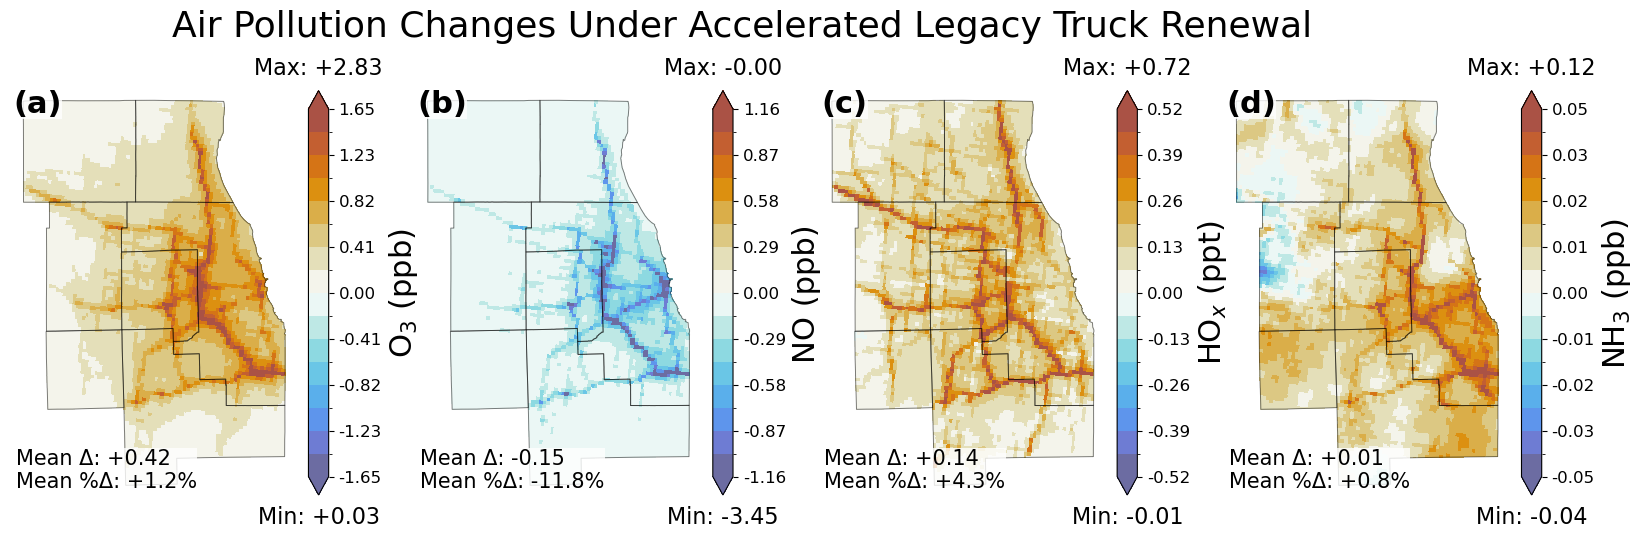

In [24]:
import cmasher as cmr

# plot annual chemistry changes under accelerated fleet renewal
N_BINS = 16
chem_species = ["O3", "NO", "HOX", "NH3"]

# set the labels, unit conversions, and rounding used for each species
chem_plot_config = {
    "O3": {"label": "O$_3$ (ppb)", "column": "O3", "decimals": 2, "scale": 1.0},
    "NO": {"label": "NO (ppb)", "column": "NO", "decimals": 2, "scale": 1.0},
    "HOX": {"label": "HO$_x$ (ppt)", "column": "HOX", "decimals": 2, "scale": 1000.0},
    "NH3": {"label": "NH$_3$ (ppb)", "column": "NH3", "decimals": 2, "scale": 1.0},
}

def plot_annual_chemistry_difference():

    fig, axs = plt.subplots(1, 4, figsize=(20, 5.5), subplot_kw={"projection": ccrs.PlateCarree()})
    fig.suptitle("Air Pollution Changes Under Accelerated Legacy Truck Renewal", fontsize=26, y=1.01)

    for i, species in enumerate(chem_species):
        ax = axs[i]
        cfg = chem_plot_config[species]
        col = cfg["column"]
        decimals = cfg["decimals"]

        # calculate the annual renewal-minus-baseline change and apply the unit conversion
        baseline_vals = cmap_base_aconc[col].astype(float).to_numpy() * cfg["scale"]
        renewal_vals = cmap_renewal_aconc[col].astype(float).to_numpy() * cfg["scale"]
        diff_vals = renewal_vals - baseline_vals

        pct_vals = np.full(diff_vals.shape, np.nan, dtype=float)
        np.divide(diff_vals, baseline_vals, out=pct_vals, where=baseline_vals != 0)
        pct_vals *= 100

        # only keep the geometry and values needed for the plot
        gdf = cmap_renewal_aconc[["geometry"]].copy()
        gdf["difference"] = diff_vals

        # center the color scale around zero using the 99th percentile
        finite_vals = diff_vals[np.isfinite(diff_vals)]
        diff_lim = max(np.quantile(np.abs(finite_vals), 0.99), 1e-6)
        bounds = np.linspace(-diff_lim, diff_lim, N_BINS + 1)
        cmap_disc = ListedColormap(cmr.prinsenvlag_r(np.linspace(0, 1, N_BINS)))
        norm = BoundaryNorm(bounds, cmap_disc.N)

        # plot the chemistry change and county boundaries
        gdf.plot(column="difference", ax=ax, cmap=cmap_disc, norm=norm, edgecolor="none", antialiased=False)
        cmap_cty.boundary.plot(ax=ax, color="black", alpha=0.5, linewidth=0.7)
        ax.set_axis_off()

        # add the panel label in the upper-left corner
        ax.text(0.01, 0.98, f"({chr(97 + i)})", transform=ax.transAxes, ha="left", va="top", fontsize=22, fontweight="bold", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 0.2}, zorder=10)

        # add the species-specific color bar
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap_disc)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax, fraction=0.06, pad=0.03, boundaries=bounds, ticks=bounds[::2], spacing="proportional", extend="both")
        cbar.ax.tick_params(labelsize=12)
        cbar.ax.yaxis.set_major_formatter(FormatStrFormatter(f"%.{decimals}f"))
        cbar.set_label(cfg["label"], fontsize=22)

        # show the actual maximum and minimum outside the color bar
        vmax_actual = float(np.nanmax(finite_vals))
        vmin_actual = float(np.nanmin(finite_vals))
        cbar.ax.text(0.5, 1.08, f"Max: {vmax_actual:+.{decimals}f}", transform=cbar.ax.transAxes, ha="center", va="bottom", fontsize=16)
        cbar.ax.text(0.5, -0.08, f"Min: {vmin_actual:+.{decimals}f}", transform=cbar.ax.transAxes, ha="center", va="top", fontsize=16)

        # add the domain-average absolute and percent changes
        mean_actual = float(np.nanmean(finite_vals))
        mean_pct = float(np.nanmean(pct_vals))
        summary_text = f"Mean Δ: {mean_actual:+.{decimals}f}\nMean %Δ: {mean_pct:+.1f}%"
        ax.text(0.02, 0.03, summary_text, transform=ax.transAxes, ha="left", va="bottom", fontsize=15, bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 0.25}, zorder=10)

    plt.savefig("SI_Fig_Renewal_Chemistry_Changes_2023.pdf", bbox_inches="tight")
    plt.savefig("SI_Fig_Renewal_Chemistry_Changes_2023.png", dpi=600, bbox_inches="tight")
    plt.show()

plot_annual_chemistry_difference()

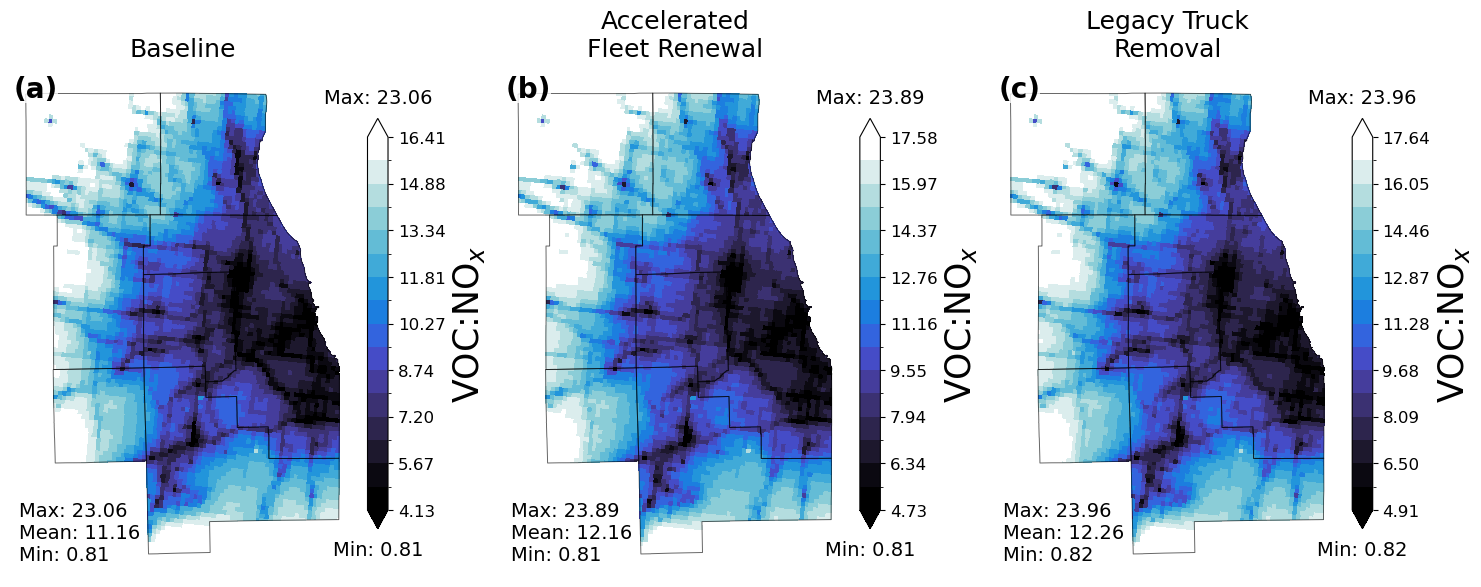

In [35]:
# plot each VOC:NOx scenario using its own color scale and color bar
N_BINS = 16
NOX_COL = "NOX"
VOC_COL = 'VOC'
# pair the VOC and NOx files used for each scenario
scenario_info = [
    ("Baseline", "Baseline", cmap_voc_base, cmap_base_aconc),
    ("Accelerated Fleet Renewal", "Accelerated\nFleet Renewal", cmap_voc_renewal, cmap_renewal_aconc),
    ("Legacy Truck Removal", "Legacy Truck\nRemoval", cmap_voc_zeropre2010s, cmap_zeropre2010s_aconc),]


# add rounded grid coordinates so the VOC and NOx files can be joined
def add_grid_coordinates(gdf):
    gdf = gdf.copy()
    points = gdf.geometry.representative_point()
    gdf["_grid_x"] = np.round(points.x, 6)
    gdf["_grid_y"] = np.round(points.y, 6)
    return gdf

# combine the VOC and NOx values and calculate the ratio for each scenario
ratio_gdfs = {}

for scenario_name, _, voc_gdf, aconc_gdf in scenario_info:
    voc_tmp = add_grid_coordinates(voc_gdf)
    nox_tmp = add_grid_coordinates(aconc_gdf)[["_grid_x", "_grid_y", NOX_COL]].copy()
    merged = voc_tmp.merge(nox_tmp, on=["_grid_x", "_grid_y"], how="left", validate="one_to_one")
    merged = gpd.GeoDataFrame(merged, geometry="geometry", crs=voc_gdf.crs)

    voc_vals = pd.to_numeric(merged[VOC_COL], errors="coerce").to_numpy()
    nox_vals = pd.to_numeric(merged[NOX_COL], errors="coerce").to_numpy()
    valid = np.isfinite(voc_vals) & np.isfinite(nox_vals) & (nox_vals > 0)

    ratio_vals = np.full(voc_vals.shape, np.nan, dtype=float)
    np.divide(voc_vals, nox_vals, out=ratio_vals, where=valid)
    merged["VOC_NOX"] = ratio_vals

    ratio_gdfs[scenario_name] = merged
   #print(f"{scenario_name}: {merged['VOC_NOX'].notna().sum()} valid grid cells")

# make one panel for each scenario with its own color scale
fig, axs = plt.subplots(1, 3, figsize=(18, 6.5), subplot_kw={"projection": ccrs.PlateCarree()})

for i, (scenario_name, title, _, _) in enumerate(scenario_info):
    ax = axs[i]
    gdf = ratio_gdfs[scenario_name]
    finite_vals = gdf["VOC_NOX"].replace([np.inf, -np.inf], np.nan).dropna().to_numpy()

    # calculate the summary statistics for this scenario
    max_ratio = float(np.nanmax(finite_vals))
    mean_ratio = float(np.nanmean(finite_vals))
    min_ratio = float(np.nanmin(finite_vals))

    # set the color scale using the ratio distribution in this panel
    vmin, vmax = np.nanquantile(finite_vals, [0.01, 0.90])

    if np.isclose(vmin, vmax):
        vmax = vmin + 1e-6

    bounds = np.linspace(vmin, vmax, N_BINS + 1)
    cmap_disc = ListedColormap(cmr.freeze(np.linspace(0, 1, N_BINS)))
    norm = BoundaryNorm(bounds, cmap_disc.N)

    # plot the VOC:NOx ratio and county boundaries
    gdf.plot(column="VOC_NOX", ax=ax, cmap=cmap_disc, norm=norm, edgecolor="none", antialiased=False, zorder=1)
    cmap_cty.boundary.plot(ax=ax, color="black", linewidth=0.7, alpha=0.6, zorder=3)

    ax.set_title(title, fontsize=18, pad=10)
    ax.set_axis_off()

    # add the panel label in the upper-left corner
    ax.text(0.01, 0.99, f"({chr(97 + i)})", transform=ax.transAxes, ha="left", va="top", fontsize=20, fontweight="bold", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 0.25}, zorder=10)

    # add the maximum, mean, and minimum in the bottom-left corner
    stats_text = f"Max: {max_ratio:.2f}\nMean: {mean_ratio:.2f}\nMin: {min_ratio:.2f}"
    ax.text(0.025, 0.025, stats_text, transform=ax.transAxes, ha="left", va="bottom", fontsize=14, color="black", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "boxstyle": "round,pad=0.30"}, zorder=10)

    # add a separate color bar for this panel
    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap_disc)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, fraction=0.05, pad=0.03, boundaries=bounds, ticks=bounds[::2], spacing="proportional", extend="both")
    cbar.ax.tick_params(labelsize=12)
    cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    cbar.set_label(r"VOC:NO$_x$", fontsize=25)

    # also show the actual maximum and minimum outside the color bar
    cbar.ax.text(0.5, 1.08, f"Max: {max_ratio:.2f}", transform=cbar.ax.transAxes, ha="center", va="bottom", fontsize=14)
    cbar.ax.text(0.5, -0.08, f"Min: {min_ratio:.2f}", transform=cbar.ax.transAxes, ha="center", va="top", fontsize=14)

plt.subplots_adjust(wspace=0.20, bottom=0.12, top=0.90)
plt.savefig("SI_VOC_NOX_Ratio_Baseline_Renewal_ZeroPre2010s.pdf", bbox_inches="tight")
plt.savefig("SI_VOC_NOX_Ratio_Baseline_Renewal_ZeroPre2010s.png", dpi=600, bbox_inches="tight")
plt.show()

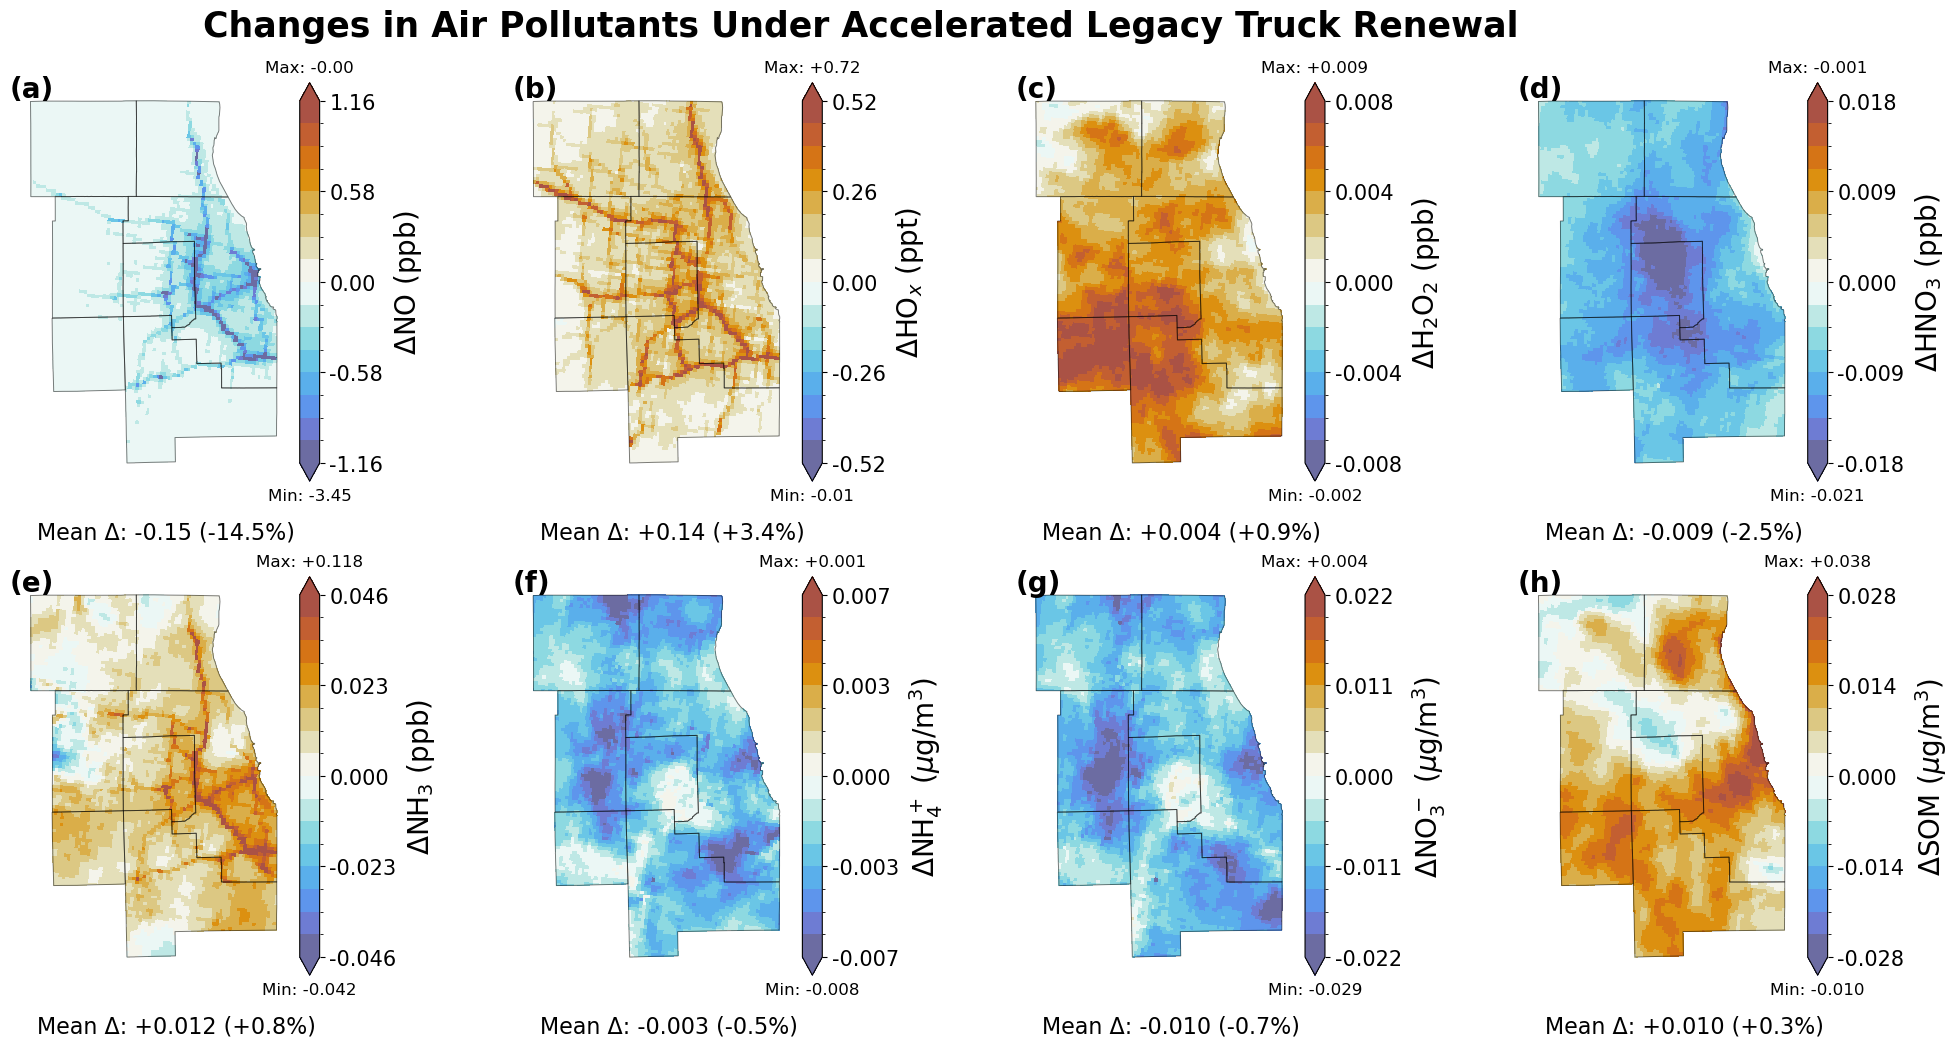

In [35]:
# ============================================================
# ACCELERATED LEGACY TRUCK RENEWAL
# Changes in oxidant chemistry and secondary aerosol
# Spatial differences = Accelerated Renewal - Baseline
# ============================================================

import cmasher as cmr

N_BINS = 16

# Keep the chemistry organized so the two rows tell a clear story
chem_species = ["NO", "HOX", "H2O2", "HNO3", "NH3", "PM25_NH4", "PM25_NO3", "ASOMIJ"]

# Put the pollutant name and units on the colorbar instead of above each map
chem_plot_config = {
    "NO": {"label": r"$\Delta$NO (ppb)", "decimals": 2, "scale": 1.0},
    "HOX": {"label": r"$\Delta$HO$_x$ (ppt)", "decimals": 2, "scale": 1000.0},
    "H2O2": {"label": r"$\Delta$H$_2$O$_2$ (ppb)", "decimals": 3, "scale": 1.0},
    "HNO3": {"label": r"$\Delta$HNO$_3$ (ppb)", "decimals": 3, "scale": 1.0},
    "NH3": {"label": r"$\Delta$NH$_3$ (ppb)", "decimals": 3, "scale": 1.0},
    "PM25_NH4": {"label": r"$\Delta$NH$_4^+$ ($\mu$g/m$^3$)", "decimals": 3, "scale": 1.0},
    "PM25_NO3": {"label": r"$\Delta$NO$_3^-$ ($\mu$g/m$^3$)", "decimals": 3, "scale": 1.0},
    "ASOMIJ": {"label": r"$\Delta$SOM ($\mu$g/m$^3$)", "decimals": 3, "scale": 1.0},
}

# All fields come from the same annual-mean ACONC files
baseline_gdf = cmap_base_aconc
renewal_gdf = cmap_renewal_aconc

# Make sure every field is available before plotting
missing_species = [col for col in chem_species if col not in baseline_gdf.columns or col not in renewal_gdf.columns]

if missing_species:
    raise KeyError(f"Missing CMAQ columns: {missing_species}")


def plot_annual_chemistry_difference():

    # Two rows of four maps
    fig, axs = plt.subplots(2, 4, figsize=(20, 10.5), subplot_kw={"projection": ccrs.PlateCarree()})
    axs = axs.flatten()

    # One title for the full figure
    fig.suptitle("Changes in Air Pollutants Under Accelerated Legacy Truck Renewal", fontsize=25, fontweight="bold", y=0.98)

    # Use the same diverging color palette for every response
    cmap_disc = ListedColormap(cmr.prinsenvlag_r(np.linspace(0, 1, N_BINS)))

    for i, (ax, species) in enumerate(zip(axs, chem_species)):

        cfg = chem_plot_config[species]
        scale = cfg["scale"]
        decimals = cfg["decimals"]

        # Accelerated Renewal minus Baseline
        baseline_vals = baseline_gdf[species].astype(float).to_numpy() * scale
        renewal_vals = renewal_gdf[species].astype(float).to_numpy() * scale
        diff_vals = renewal_vals - baseline_vals

        # Only retain the geometry and the field I am plotting
        plot_gdf = renewal_gdf[["geometry"]].copy()
        plot_gdf["difference"] = diff_vals

        # Calculate the domain-average absolute and percent changes
        baseline_mean = float(np.nanmean(baseline_vals))
        renewal_mean = float(np.nanmean(renewal_vals))
        mean_delta = float(np.nanmean(diff_vals))
        mean_pct = ((renewal_mean - baseline_mean) / baseline_mean) * 100 if not np.isclose(baseline_mean, 0) else np.nan

        # Use a symmetric 99th-percentile scale so a few extreme cells do not control the map
        finite_vals = diff_vals[np.isfinite(diff_vals)]
        diff_lim = np.quantile(np.abs(finite_vals), 0.99)

        if np.isclose(diff_lim, 0):
            diff_lim = 1e-6

        bounds = np.linspace(-diff_lim, diff_lim, N_BINS + 1)
        norm = BoundaryNorm(bounds, cmap_disc.N)

        # Plot the concentration response
        plot_gdf.plot(column="difference", ax=ax, cmap=cmap_disc, norm=norm, edgecolor="none", antialiased=False)
        cmap_cty.boundary.plot(ax=ax, color="black", alpha=0.5, linewidth=0.7)
        ax.set_axis_off()

        # Panels a-h
        ax.text(-0.03, 1.02, f"({chr(97 + i)})", transform=ax.transAxes, ha="left", va="top", fontsize=20, fontweight="bold", zorder=10)

        # Use the colorbar to identify the pollutant and its units
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap_disc)
        sm.set_array([])

        cbar = fig.colorbar(sm, ax=ax, fraction=0.055, pad=0.025, boundaries=bounds, ticks=bounds[::4], spacing="proportional", extend="both")
        cbar.set_label(cfg["label"], fontsize=20, labelpad=6)
        cbar.ax.tick_params(labelsize=15)
        cbar.ax.yaxis.set_major_formatter(FormatStrFormatter(f"%.{decimals}f"))

        # Keep the actual domain extrema visible
        vmax_actual = float(np.nanmax(finite_vals))
        vmin_actual = float(np.nanmin(finite_vals))

        cbar.ax.text(0.5, 1.07, f"Max: {vmax_actual:+.{decimals}f}", transform=cbar.ax.transAxes, ha="center", va="bottom", fontsize=12)
        cbar.ax.text(0.5, -0.07, f"Min: {vmin_actual:+.{decimals}f}", transform=cbar.ax.transAxes, ha="center", va="top", fontsize=12)

        # Add the domain-average absolute and percent changes below each map
        ax.text(0.07, -0.1, f"Mean Δ: {mean_delta:+.{decimals}f} ({mean_pct:+.1f}%)", transform=ax.transAxes, ha="left", va="top", fontsize=16)

        del plot_gdf, baseline_vals, renewal_vals, diff_vals

    # Leave room for the colorbars and statistics without using subplot headers
    fig.subplots_adjust(left=0.025, right=0.985, top=0.91, bottom=0.06, hspace=0.24, wspace=0.22)

    plt.savefig("SI_Renewal_Oxidant_SecondaryAerosol_Changes.pdf", bbox_inches="tight")
    plt.savefig("SI_Renewal_Oxidant_SecondaryAerosol_Changes.png", dpi=500, bbox_inches="tight")
    plt.show()


plot_annual_chemistry_difference()

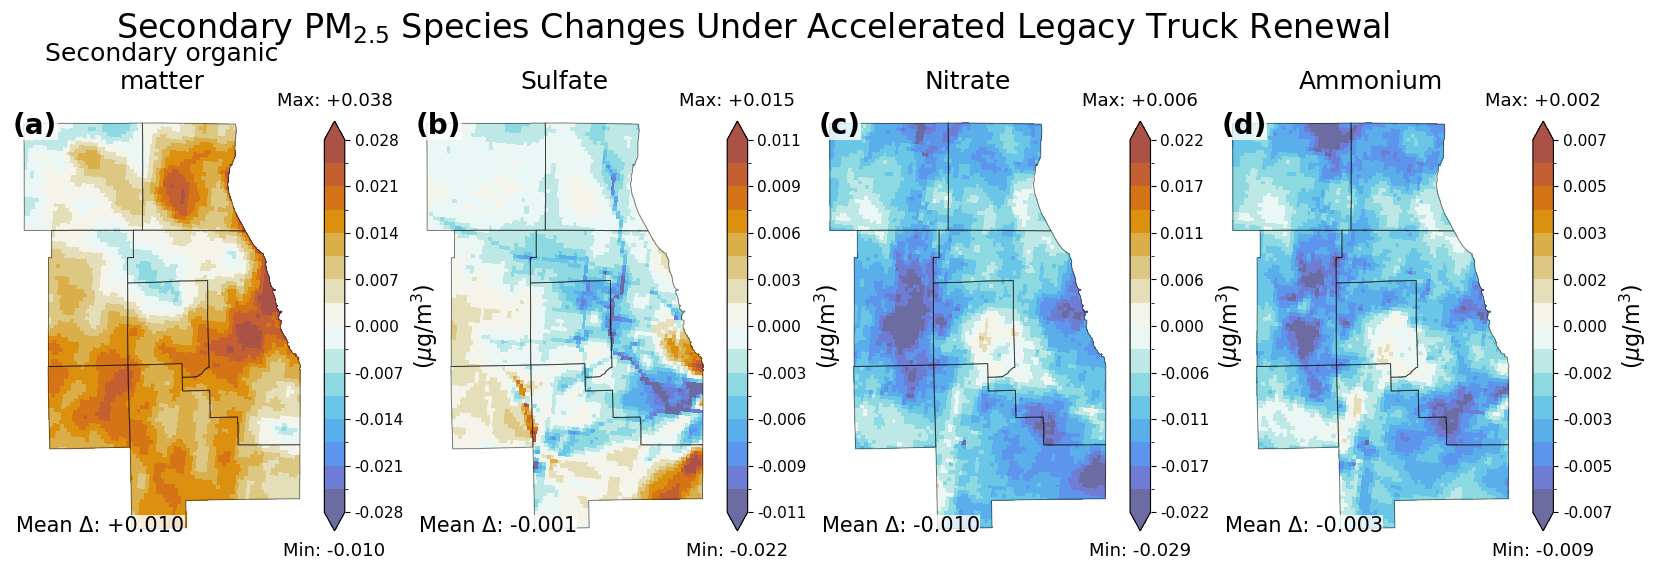

In [37]:
# plot the change in each secondary-associated fine-mode PM component
N_BINS = 16
component_order = ["Secondary organic matter", "Sulfate", "Nitrate", "Ammonium"]

# pair each component with its CMAQ aggregate and figure label
secondary_pm_components = {
    "Secondary organic matter": {"column": "ASOMIJ", "label": "Secondary organic\nmatter", "decimals": 3},
    "Sulfate": {"column": "ASO4IJ", "label": "Sulfate", "decimals": 3},
    "Nitrate": {"column": "ANO3IJ", "label": "Nitrate", "decimals": 3},
    "Ammonium": {"column": "ANH4IJ", "label": "Ammonium", "decimals": 3},
}

# make one panel for each secondary PM component
fig, axs = plt.subplots(1, 4, figsize=(20, 5.8), subplot_kw={"projection": ccrs.PlateCarree()})
fig.suptitle("Secondary PM$_{2.5}$ Species Changes Under Accelerated Legacy Truck Renewal", fontsize=24, y=1.04)

for i, component in enumerate(component_order):
    ax = axs[i]
    cfg = secondary_pm_components[component]
    col = cfg["column"]
    decimals = cfg["decimals"]

    if col not in cmap_base_aconc.columns or col not in cmap_renewal_aconc.columns:
        raise KeyError(f"Missing CMAQ species: {col}")

    # calculate the accelerated-renewal-minus-baseline change
    baseline_vals = pd.to_numeric(cmap_base_aconc[col], errors="coerce").to_numpy()
    renewal_vals = pd.to_numeric(cmap_renewal_aconc[col], errors="coerce").to_numpy()
    diff_vals = renewal_vals - baseline_vals
    finite_vals = diff_vals[np.isfinite(diff_vals)]

    # calculate the domain-wide summary statistics
    max_diff = float(np.nanmax(finite_vals))
    mean_diff = float(np.nanmean(finite_vals))
    min_diff = float(np.nanmin(finite_vals))

    # only keep the geometry and concentration change needed for the plot
    gdf = cmap_renewal_aconc[["geometry"]].copy()
    gdf["difference"] = diff_vals

    # center each color scale around zero using the 99th percentile
    diff_lim = max(np.nanquantile(np.abs(finite_vals), 0.99), 1e-6)
    bounds = np.linspace(-diff_lim, diff_lim, N_BINS + 1)
    cmap_disc = ListedColormap(cmr.prinsenvlag_r(np.linspace(0, 1, N_BINS)))
    norm = BoundaryNorm(bounds, cmap_disc.N)

    # plot the concentration change and county boundaries
    gdf.plot(column="difference", ax=ax, cmap=cmap_disc, norm=norm, edgecolor="none", antialiased=False, zorder=1)
    cmap_cty.boundary.plot(ax=ax, color="black", alpha=0.5, linewidth=0.7, zorder=3)

    ax.set_title(cfg["label"], fontsize=18, pad=10)
    ax.set_axis_off()

    # add the panel label in the upper-left corner
    ax.text(0.01, 0.98, f"({chr(97 + i)})", transform=ax.transAxes, ha="left", va="top", fontsize=20, fontweight="bold", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 0.2}, zorder=10)

    # add the domain-average concentration change
    ax.text(0.02, 0.03, f"Mean Δ: {mean_diff:+.{decimals}f}", transform=ax.transAxes, ha="left", va="bottom", fontsize=15, bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 0.25}, zorder=10)

    # add an individual color bar for each component
    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap_disc)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, fraction=0.06, pad=0.03, boundaries=bounds, ticks=bounds[::2], spacing="proportional", extend="both")
    cbar.ax.tick_params(labelsize=11)
    cbar.ax.yaxis.set_major_formatter(FormatStrFormatter(f"%.{decimals}f"))
    cbar.set_label(r"($\mu$g/m$^3$)", fontsize=16)

    # show the actual maximum and minimum outside the color bar
    cbar.ax.text(0.5, 1.08, f"Max: {max_diff:+.{decimals}f}", transform=cbar.ax.transAxes, ha="center", va="bottom", fontsize=13)
    cbar.ax.text(0.5, -0.08, f"Min: {min_diff:+.{decimals}f}", transform=cbar.ax.transAxes, ha="center", va="top", fontsize=13)

plt.subplots_adjust(wspace=0.18)
plt.savefig("SI_Fig_Renewal_Secondary_PM25_Species_Changes_2023.pdf", bbox_inches="tight")
plt.savefig("SI_Fig_Renewal_Secondary_PM25_Species_Changes_2023.png", dpi=600, bbox_inches="tight")
plt.show()

In [39]:
baseline_gdf = cmap_base_aconc
renewal_gdf = cmap_renewal_aconc

# Include every derived PM2.5 field available in both files
pm25_species = [col for col in baseline_gdf.columns if col.startswith("PM25_") and col in renewal_gdf.columns]

# Add the detailed primary and secondary aerosol fields I want to examine
detailed_pm25_species = [
    "AECIJ", "APOCIJ", "APOMIJ",                    # elemental carbon and primary organic aerosol
    "ASOCIJ", "ASOMIJ",                            # secondary organic aerosol
    "AORGAIJ", "AORGBIJ", "AORGCJ",               # secondary organic aerosol groups
    "ANO3IJ", "ANO3K",                             # particulate nitrate
    "ANH4IJ", "ANH4K",                             # particulate ammonium
    "ASO4IJ", "ASO4K",                             # particulate sulfate
    "ASOILJ", "AUNSPEC1IJ", "AUNSPEC2IJ",          # soil and unspecified aerosol
    "PMAMS_CL", "PMAMS_NH4", "PMAMS_NO3",          # aerosol mass components
    "PMAMS_OA", "PMAMS_SO4",
    "PMIJ_FRM", "PM1_TOT",                         # additional fine-particle totals
]

# Keep the original order and remove duplicates or missing fields
all_pm25_species = list(dict.fromkeys(pm25_species + detailed_pm25_species))
missing_species = [col for col in all_pm25_species if col not in baseline_gdf.columns or col not in renewal_gdf.columns]
all_pm25_species = [col for col in all_pm25_species if col in baseline_gdf.columns and col in renewal_gdf.columns]

print(f"Calculating statistics for {len(all_pm25_species)} PM2.5 fields.")
print(f"Missing fields skipped: {missing_species}")

rows = []

for species in all_pm25_species:

    baseline_vals = baseline_gdf[species].astype(float).to_numpy()
    renewal_vals = renewal_gdf[species].astype(float).to_numpy()
    diff_vals = renewal_vals - baseline_vals

    # Only calculate grid-cell percentages where both values are finite and the baseline is positive
    valid_pct = np.isfinite(baseline_vals) & np.isfinite(renewal_vals) & (baseline_vals > 0)
    pct_vals = np.full(baseline_vals.shape, np.nan)
    pct_vals[valid_pct] = (diff_vals[valid_pct] / baseline_vals[valid_pct]) * 100

    # The mean percentage is the change between domain means
    baseline_mean = float(np.nanmean(baseline_vals))
    renewal_mean = float(np.nanmean(renewal_vals))
    mean_pct = ((renewal_mean - baseline_mean) / baseline_mean) * 100 if not np.isclose(baseline_mean, 0) else np.nan

    rows.append({
        "Species": species,
        "Baseline Min": float(np.nanmin(baseline_vals)),
        "Baseline Max": float(np.nanmax(baseline_vals)),
        "Baseline Mean": baseline_mean,
        "Renewal Min": float(np.nanmin(renewal_vals)),
        "Renewal Max": float(np.nanmax(renewal_vals)),
        "Renewal Mean": renewal_mean,
        "Difference Min": float(np.nanmin(diff_vals)),
        "Difference Max": float(np.nanmax(diff_vals)),
        "Difference Mean": float(np.nanmean(diff_vals)),
        "Minimum %Δ": float(np.nanmin(pct_vals)),
        "Maximum %Δ": float(np.nanmax(pct_vals)),
        "Mean %Δ": mean_pct,
    })

pm25_summary = pd.DataFrame(rows)

# Print the full results without truncating columns or rows
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 240):
    print(
        pm25_summary.to_string(
            index=False,
            formatters={
                "Baseline Min": "{:.4f}".format,
                "Baseline Max": "{:.4f}".format,
                "Baseline Mean": "{:.4f}".format,
                "Renewal Min": "{:.4f}".format,
                "Renewal Max": "{:.4f}".format,
                "Renewal Mean": "{:.4f}".format,
                "Difference Min": "{:+.4f}".format,
                "Difference Max": "{:+.4f}".format,
                "Difference Mean": "{:+.4f}".format,
                "Minimum %Δ": "{:+.2f}%".format,
                "Maximum %Δ": "{:+.2f}%".format,
                "Mean %Δ": "{:+.2f}%".format,
            },
        )
    )

Calculating statistics for 41 PM2.5 fields.
Missing fields skipped: []
   Species Baseline Min Baseline Max Baseline Mean Renewal Min Renewal Max Renewal Mean Difference Min Difference Max Difference Mean Minimum %Δ Maximum %Δ Mean %Δ
   PM25_HP       0.0000       0.0006        0.0001      0.0000      0.0006       0.0001        -0.0001        +0.0000         -0.0000    -37.40%    +48.54%  -3.04%
   PM25_CL       0.0177       0.1172        0.0298      0.0180      0.1175       0.0299        -0.0029        +0.0031         +0.0000     -9.20%    +11.82%  +0.07%
   PM25_EC       0.1600       0.8224        0.2938      0.1553      0.7536       0.2620        -0.3226        -0.0031         -0.0317    -45.28%     -1.79% -10.80%
   PM25_NA       0.0336       0.2144        0.0418      0.0336      0.2137       0.0418        -0.0011        +0.0012         -0.0001     -1.59%     +1.61%  -0.15%
   PM25_MG       0.0095       0.0360        0.0118      0.0095      0.0361       0.0118        -0.0002       